# Ames Housing Price Prediction

In [ ]:
#12/9 full project  final version

# Core imports
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as sps
from scipy.stats import f_oneway

from sklearn.model_selection import train_test_split, GridSearchCV,KFold,cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge,Lasso

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 100)

## 1. Dataset Understanding

In [2]:
df_raw = pd.read_csv("AmesHousing.csv") 
df_raw . head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [3]:
# Normalize column names (remove spaces / slashes) so they behave as valid identifiers,
# e.g. "Lot Area" -> "LotArea", "1st Flr SF" -> "1stFlrSF"
df_raw.columns = [c.replace(" ", "").replace("/", "") for c in df_raw.columns]

print("Shape:", df_raw.shape)

# Drop identifier columns (no predictive value)
df = df_raw.drop(columns=["Order", "PID"]).copy()

print("Shape after dropping identifiers:", df.shape)
print("\nData types:")
print(df.dtypes.value_counts())
print("\nNumber of duplicate rows:", df.duplicated().sum())

df.head()

Shape: (2930, 82)
Shape after dropping identifiers: (2930, 80)

Data types:
object     43
int64      26
float64    11
Name: count, dtype: int64

Number of duplicate rows: 0


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [4]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
print(f"Columns with missing values: {len(missing_table)} out of {df.shape[1]}")
missing_table

Columns with missing values: 27 out of 80


,missing_count,missing_pct
PoolQC,2917,99.56
MiscFeature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
MasVnrType,1775,60.58
FireplaceQu,1422,48.53
LotFrontage,490,16.72
GarageQual,159,5.43
GarageCond,159,5.43
GarageYrBlt,159,5.43


**Reading the missing-value table:** for many of these columns (e.g. `PoolQC`, `Alley`,
`Fence`, `FireplaceQu`, `GarageType`, `BsmtQual`, `MasVnrType`) a missing value does **not** mean
the data is unknown — the data dictionary tells us `NA` literally means *"the house does not have
this feature"* (no pool, no alley, no fireplace, no garage, no basement, ...). Only a handful of
columns (`LotFrontage`, `MasVnrArea`, `Electrical`, a few basement/garage numeric fields) are
genuinely missing values that need imputation. This distinction drives our preprocessing strategy
in Section 4.

### Identifying feature types

Based on the data dictionary (`data_description.txt`) we split the 79 predictor columns into three
groups:

- **Numerical** (continuous/discrete measurements — areas, counts, years, ratings already encoded
  as 1–10 such as `OverallQual`/`OverallCond`): 34 columns.
- **Nominal categorical** (unordered categories — e.g. `Neighborhood`, `MSZoning`,
  `Exterior1st`, `SaleType`, `MoSold`): 25 columns.
- **Ordinal categorical** (categories with a natural rank — quality/condition scales like
  `ExterQual`, `BsmtQual`, `KitchenQual`, `GarageFinish`, `Functional`, `PavedDrive`, `Utilities`):
  20 columns.

**Some of the most important variables:**
- `OverallQual` — overall material/finish rating (1–10): historically the single strongest
  predictor of `SalePrice` in this dataset.
- `GrLivArea` — above-ground living area in sq.ft.: strongly, roughly linearly related to price.
- `Neighborhood` — location is a classic real-estate price driver.
- `YearBuilt` / `YearRemodAdd` — newer / recently remodeled homes command higher prices.
- `TotalBsmtSF`, `GarageCars`, `FullBath` — size/amenity features that add value.

## Feature Engineering 

In [5]:
# Columns where NaN literally means "feature not present" -> fill with the sentinel "NA"
# (already a valid category level in the data dictionary), BEFORE assigning ordinal encodings.
none_means_missing_cols = [
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence",
    "Alley", "MiscFeature", "GarageType", "MasVnrType",
]
for c in none_means_missing_cols:
    df[c] = df[c].fillna("NA")

# Ordinal features -> explicit rank order (low -> high), taken directly from data_description.txt
ordinal_features = {
    "LotShape":     ["IR3", "IR2", "IR1", "Reg"],
    "LandSlope":    ["Sev", "Mod", "Gtl"],
    "ExterQual":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "ExterCond":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtQual":     ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtCond":     ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtExposure": ["NA", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "HeatingQC":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual":  ["Po", "Fa", "TA", "Gd", "Ex"],
    "Functional":   ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "FireplaceQu":  ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageFinish": ["NA", "Unf", "RFn", "Fin"],
    "GarageQual":   ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageCond":   ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "PavedDrive":   ["N", "P", "Y"],
    "PoolQC":       ["NA", "Fa", "TA", "Gd", "Ex"],
    "Fence":        ["NA", "MnWw", "GdWo", "MnPrv", "GdPrv"],
    "Utilities":    ["ELO", "NoSeWa", "NoSewr", "AllPub"],
}
ordinal_cols = list(ordinal_features.keys())

nominal_cols = [
    "MSSubClass", "MSZoning", "Street", "Alley", "LandContour", "LotConfig",
    "Neighborhood", "Condition1", "Condition2", "BldgType", "HouseStyle",
    "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd", "MasVnrType",
    "Foundation", "Heating", "CentralAir", "Electrical", "GarageType",
    "MiscFeature", "SaleType", "SaleCondition", "MoSold",
]

target = "SalePrice"
exclude = set(ordinal_cols) | set(nominal_cols) | {target}
numerical_cols = [c for c in df.columns if c not in exclude]

print(f"Numerical features   : {len(numerical_cols)}")
print(f"Nominal features     : {len(nominal_cols)}")
print(f"Ordinal features     : {len(ordinal_cols)}")
assert set(numerical_cols) | set(nominal_cols) | set(ordinal_cols) | {target} == set(df.columns)
print("\nAll 79 predictor columns accounted for, no overlaps.")

Numerical features   : 34
Nominal features     : 25
Ordinal features     : 20

All 79 predictor columns accounted for, no overlaps.


# 2. Exploratry Data Analysis EDA

In [6]:
df[numerical_cols + [target]].describe().T

,count,mean,std,min,25%,50%,75%,max
LotFrontage,2440.0,69.224590,23.365335,21.0,58.00,68.0,80.00,313.0
LotArea,2930.0,10147.921843,7880.017759,1300.0,7440.25,9436.5,11555.25,215245.0
OverallQual,2930.0,6.094881,1.411026,1.0,5.00,6.0,7.00,10.0
OverallCond,2930.0,5.563140,1.111537,1.0,5.00,5.0,6.00,9.0
YearBuilt,2930.0,1971.356314,30.245361,1872.0,1954.00,1973.0,2001.00,2010.0
YearRemodAdd,2930.0,1984.266553,20.860286,1950.0,1965.00,1993.0,2004.00,2010.0
MasVnrArea,2907.0,101.896801,179.112611,0.0,0.00,0.0,164.00,1600.0
BsmtFinSF1,2929.0,442.629566,455.590839,0.0,0.00,370.0,734.00,5644.0
BsmtFinSF2,2929.0,49.722431,169.168476,0.0,0.00,0.0,0.00,1526.0
BsmtUnfSF,2929.0,559.262547,439.494153,0.0,219.00,466.0,802.00,2336.0


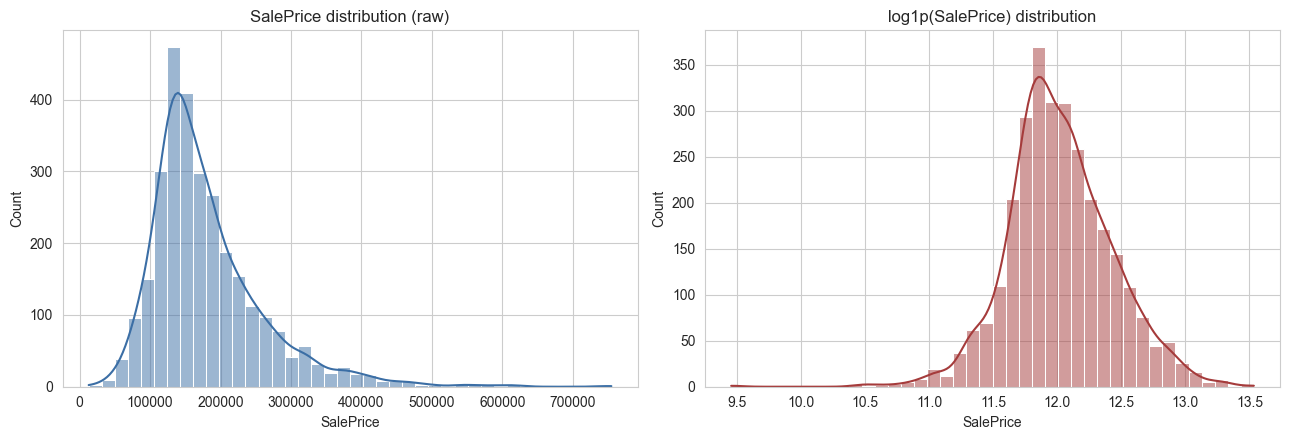

SalePrice skewness (raw): 1.744
SalePrice skewness (log1p): -0.015


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df[target], kde=True, bins=40, ax=axes[0], color="#3b6ea5")
axes[0].set_title("SalePrice distribution (raw)")
sns.histplot(np.log1p(df[target]), kde=True, bins=40, ax=axes[1], color="#a53b3b")
axes[1].set_title("log1p(SalePrice) distribution")
plt.tight_layout()
plt.show()

print("SalePrice skewness (raw):", round(df[target].skew(), 3))
print("SalePrice skewness (log1p):", round(np.log1p(df[target]).skew(), 3))

**Finding:** `SalePrice` is strongly right-skewed (skew ≈ 1.74) — most homes sell in the
\$100k–\$250k range but a long tail of expensive homes pulls the mean above the median. A
`log1p` transform makes the distribution nearly symmetric (skew ≈ 0.05), which is important
because linear models (and RMSE-based training) assume roughly homoscedastic, normally distributed
errors. We will train models on `log1p(SalePrice)` and always convert predictions back with
`expm1` before reporting metrics in dollars.

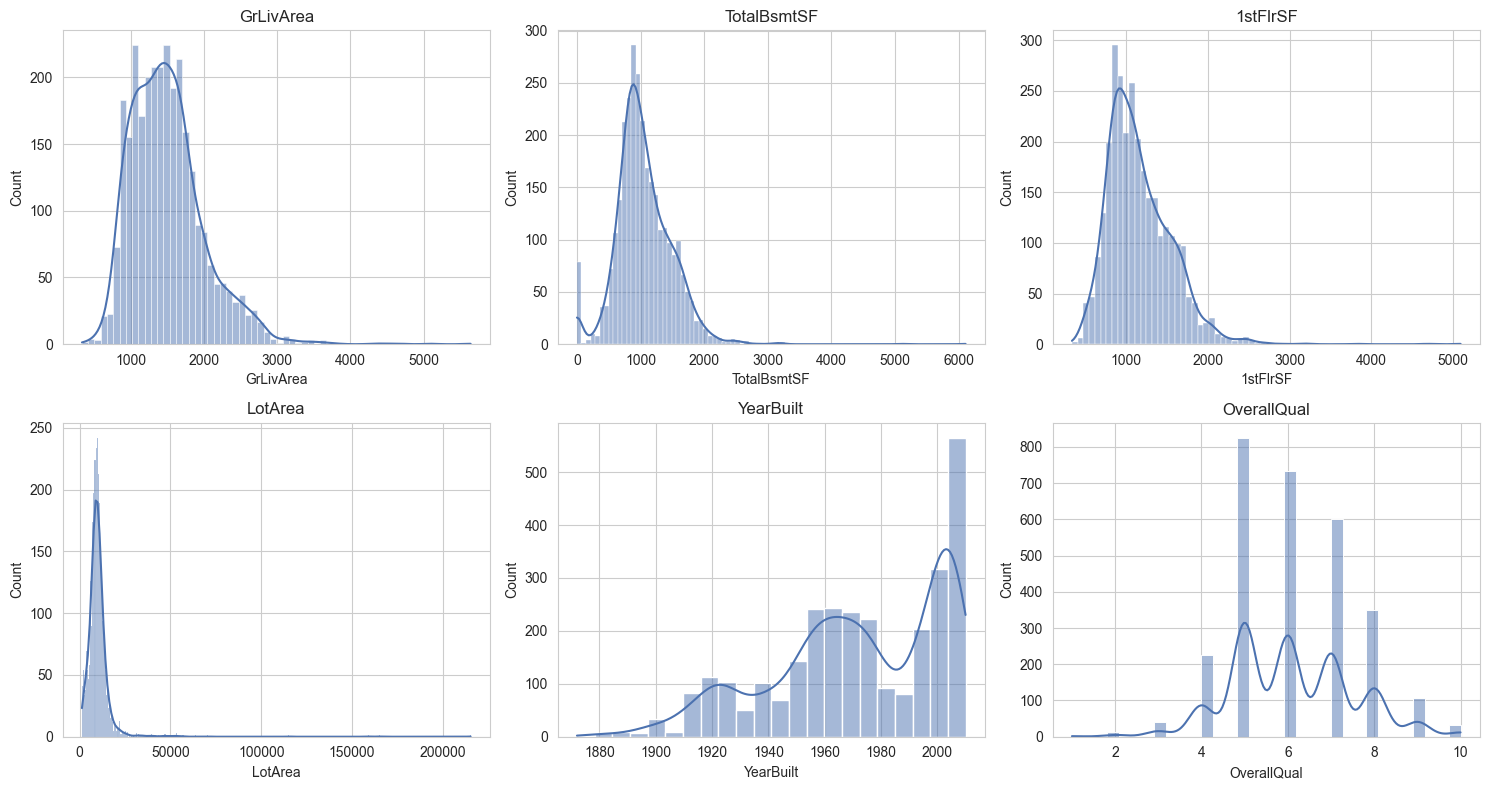

In [ ]:
## The distribution of the numerical features

num_to_plot = ["GrLivArea", "TotalBsmtSF", "1stFlrSF", "LotArea", "YearBuilt", "OverallQual"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_to_plot):
    sns.histplot(df[col], kde=True, ax=ax, color="#4c72b0")
    ax.set_title(col)
plt.tight_layout()
plt.show()


# GrLivArea, TotalBsmtSF, 1stFlrSF, and LotArea are right-skewed with some high-value observations.
# YearBuilt is concentrated in more recent construction years.
# OverallQual is a discrete feature with most houses having medium to high quality ratings.
# Overall, the distributions show that several numerical features are skewed and may need
# transformation before applying regression models.

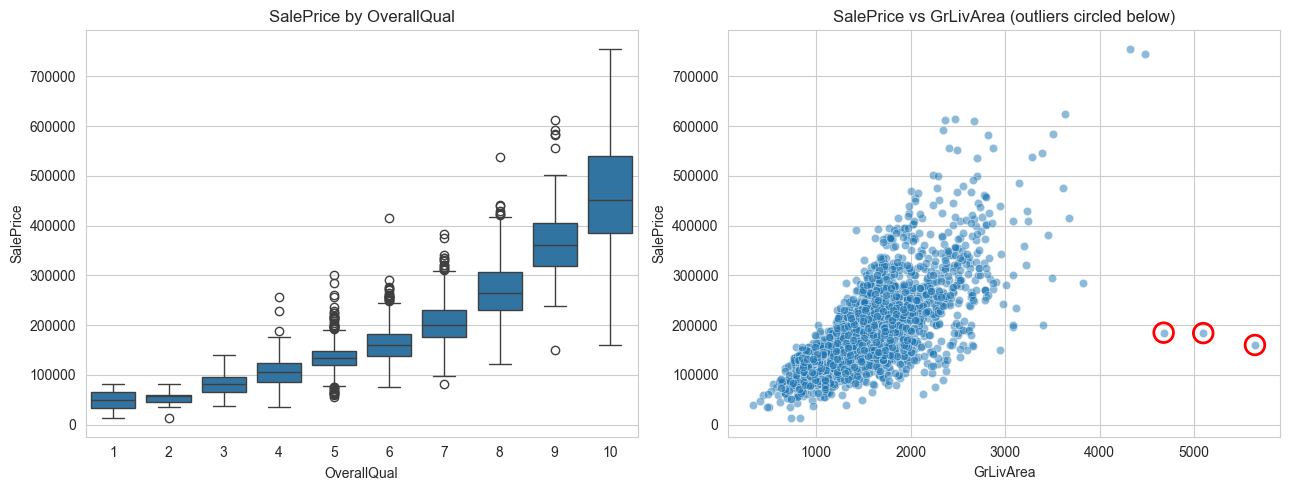

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(x=df["OverallQual"], y=df[target], ax=axes[0])
axes[0].set_title("SalePrice by OverallQual")
sns.scatterplot(x=df["GrLivArea"], y=df[target], ax=axes[1], alpha=0.5)
axes[1].set_title("SalePrice vs GrLivArea (outliers circled below)")
axes[1].scatter(df.loc[(df.GrLivArea > 4000) & (df.SalePrice < 300000), "GrLivArea"],
                df.loc[(df.GrLivArea > 4000) & (df.SalePrice < 300000), target],
                s=200, facecolors="none", edgecolors="red", linewidths=2)
plt.tight_layout()
plt.show()

# The boxplot shows a strong positive relationship between OverallQual and SalePrice. 
#Higher-quality houses tend to have higher sale prices


#"The first plot shows that SalePrice generally increases as OverallQual increases. The second plot shows a positive relationship between GrLivArea and SalePrice, 
# while the circled observations represent houses with unusually large living areas but relatively low prices.

**Outlier finding:** a handful of houses have very large `GrLivArea` (>4000 sq.ft.) yet sold
for unexpectedly *low* prices (circled in red — 3 houses under \$300k despite being amongst the
biggest homes in the dataset). This is a well-documented data quirk of the Ames dataset (the data's
original author recommends removing them) — they are likely partial/incomplete or distressed
sales that don't reflect normal market behaviour and would otherwise badly distort a regression
model (especially linear/SVR fits) by pulling the fitted trend away from the true relationship. We
remove these 3 rows before modeling (Section 4).

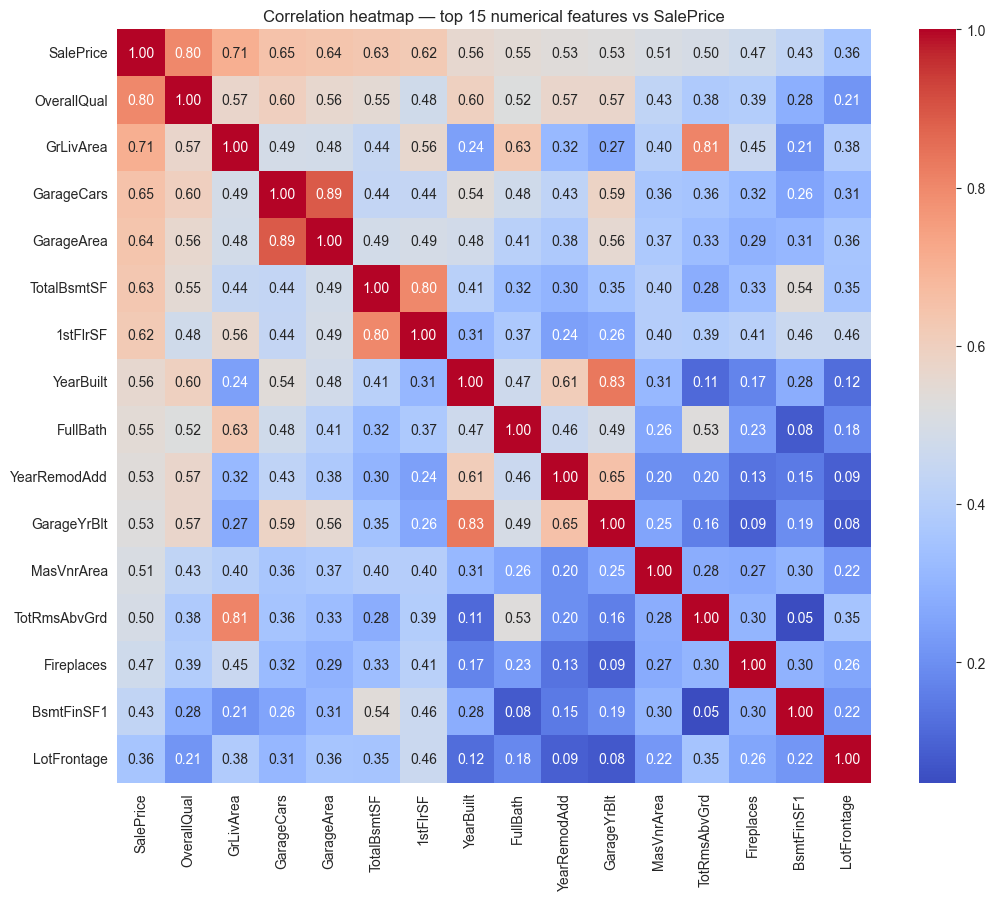

Top correlated numerical features with SalePrice:
SalePrice       1.000000
OverallQual     0.799262
GrLivArea       0.706780
GarageCars      0.647877
GarageArea      0.640401
TotalBsmtSF     0.632280
1stFlrSF        0.621676
YearBuilt       0.558426
FullBath        0.545604
YearRemodAdd    0.532974
GarageYrBlt     0.526965
Name: SalePrice, dtype: float64


In [10]:
corr = df[numerical_cols + [target]].corr(numeric_only=True)
top_corr = corr[target].abs().sort_values(ascending=False).head(16).index
plt.figure(figsize=(11, 9))
sns.heatmap(df[top_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation heatmap — top 15 numerical features vs SalePrice")
plt.tight_layout()
plt.show()

print("Top correlated numerical features with SalePrice:")
print(corr[target].abs().sort_values(ascending=False).head(11))

# 3. Data Analysis & Insights 

## Housing Prices 

### 1.What is the average, median, minimum, and maximum SalePrice? 

In [11]:
# Compute the key summary statistics for the target variable

price_stats = df["SalePrice"].agg(["mean", "median", "min", "max", "std"]).round(0)
print(price_stats)


# Insight:
# The most expensive houses tend to combine high OverallQual,
# large living areas, larger garages, newer construction,
# and premium neighborhoods.
# This suggests that high SalePrice is associated with a combination
# of quality, size, amenities, and location.

mean      180796.0
median    160000.0
min        12789.0
max       755000.0
std        79887.0
Name: SalePrice, dtype: float64


### 2.Which houses have the highest and lowest sale prices?

Top 5 most expensive houses:
      SalePrice  GrLivArea  OverallQual Neighborhood  YearBuilt
1767     755000       4316           10      NoRidge       1994
1760     745000       4476           10      NoRidge       1996
2445     625000       3627           10      NoRidge       1995
1063     615000       2470           10      NridgHt       2003
44       611657       2364            9      NridgHt       2009

Bottom 5 cheapest houses:
      SalePrice  GrLivArea  OverallQual Neighborhood  YearBuilt
181       12789        832            2      OldTown       1923
1553      13100        733            1       IDOTRR       1952
726       34900        720            4       IDOTRR       1920
2843      35000        498            2      Edwards       1922
2880      35311        480            2       IDOTRR       1949


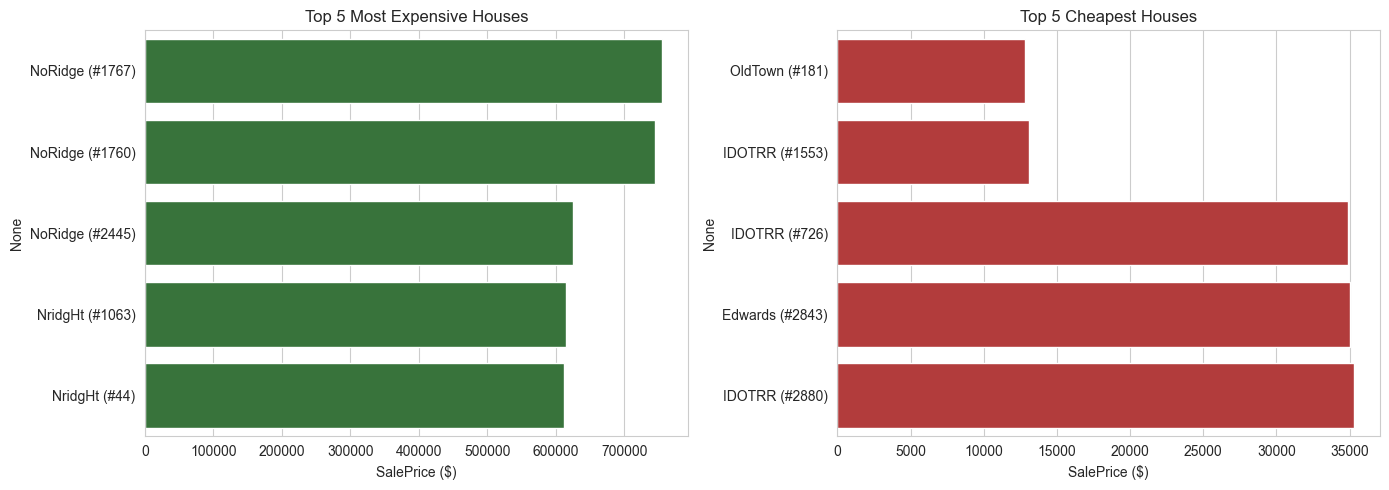

In [12]:
# Top 5 most expensive houses
top5 = df.nlargest(5, "SalePrice")[
    ["SalePrice", "GrLivArea", "OverallQual", "Neighborhood", "YearBuilt"]
]
print("Top 5 most expensive houses:")
print(top5)

# Bottom 5 cheapest houses
bottom5 = df.nsmallest(5, "SalePrice")[
    ["SalePrice", "GrLivArea", "OverallQual", "Neighborhood", "YearBuilt"]
]
print("\nBottom 5 cheapest houses:")
print(bottom5)

# Visualize both side by side for a quick visual comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    x=top5["SalePrice"].values,
    y=top5["Neighborhood"] + " (#" + top5.index.astype(str) + ")",
    ax=axes[0], color="#2e7d32"
)
axes[0].set_title("Top 5 Most Expensive Houses")
axes[0].set_xlabel("SalePrice ($)")

sns.barplot(
    x=bottom5["SalePrice"].values,
    y=bottom5["Neighborhood"] + " (#" + bottom5.index.astype(str) + ")",
    ax=axes[1], color="#c62828"
)
axes[1].set_title("Top 5 Cheapest Houses")
axes[1].set_xlabel("SalePrice ($)")

plt.tight_layout()
plt.show()

# Insight: the highest-priced homes combine three things at once -- top
# overall quality, large living area, AND a premium neighborhood -- while the
# lowest-priced homes are small, low-quality, and old, concentrated in the
# same few lower-priced neighborhoods. This shows SalePrice is driven by a
# *combination* of quality + size + location, not any single factor alone.


### 3.How does house price vary with living area (GrLivArea)?

Correlation(GrLivArea, SalePrice) = 0.707


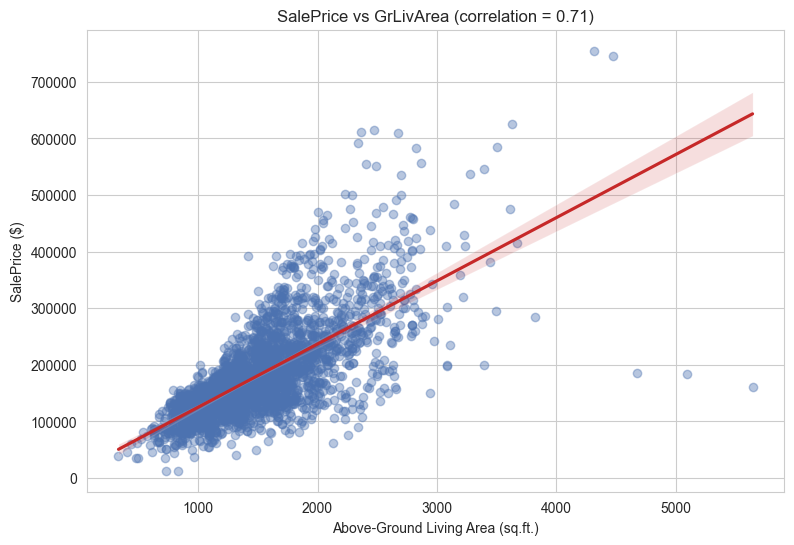

In [13]:
# Correlation between living area and sale price
corr_value = df["GrLivArea"].corr(df["SalePrice"])
print(f"Correlation(GrLivArea, SalePrice) = {corr_value:.3f}")

# Visualize the relationship with a scatterplot + regression trend line
plt.figure(figsize=(9, 6))
sns.regplot(
    x="GrLivArea", y="SalePrice", data=df,
    scatter_kws={"alpha": 0.4, "color": "#4c72b0"},
    line_kws={"color": "#c62828"}
)
plt.title(f"SalePrice vs GrLivArea (correlation = {corr_value:.2f})")
plt.xlabel("Above-Ground Living Area (sq.ft.)")
plt.ylabel("SalePrice ($)")
plt.show()

# Insight: living area is one of the strongest single predictors of price in
# the dataset -- bigger homes sell for more, as expected. Note the handful of
# points at the far right (GrLivArea > 4000 sq.ft.) that sit far BELOW the
# trend line: these are the known outlier houses (large but cheap, likely
# incomplete/distressed sales) that we remove before modeling, since they
# would otherwise distort the fitted relationship for both Linear Regression
# and SVR.

### 4.What are the characteristics of the most expensive houses?

      SalePrice  OverallQual  GrLivArea  TotalBsmtSF  GarageCars  FullBath  \
1767     755000           10       4316       2444.0         3.0         3   
1760     745000           10       4476       2396.0         3.0         3   
2445     625000           10       3627       1930.0         3.0         3   
1063     615000           10       2470       2535.0         3.0         1   
44       611657            9       2364       2330.0         3.0         2   
432      610000           10       2674       2630.0         3.0         2   
1637     591587            9       2338       2660.0         3.0         2   
2450     584500            9       3500       1733.0         3.0         3   
433      582933            9       2822       1734.0         3.0         3   
2332     556581            9       2868       1992.0         3.0         3   
423      555000           10       2402       3094.0         3.0         2   
456      552000           10       2492       2492.0         3.0

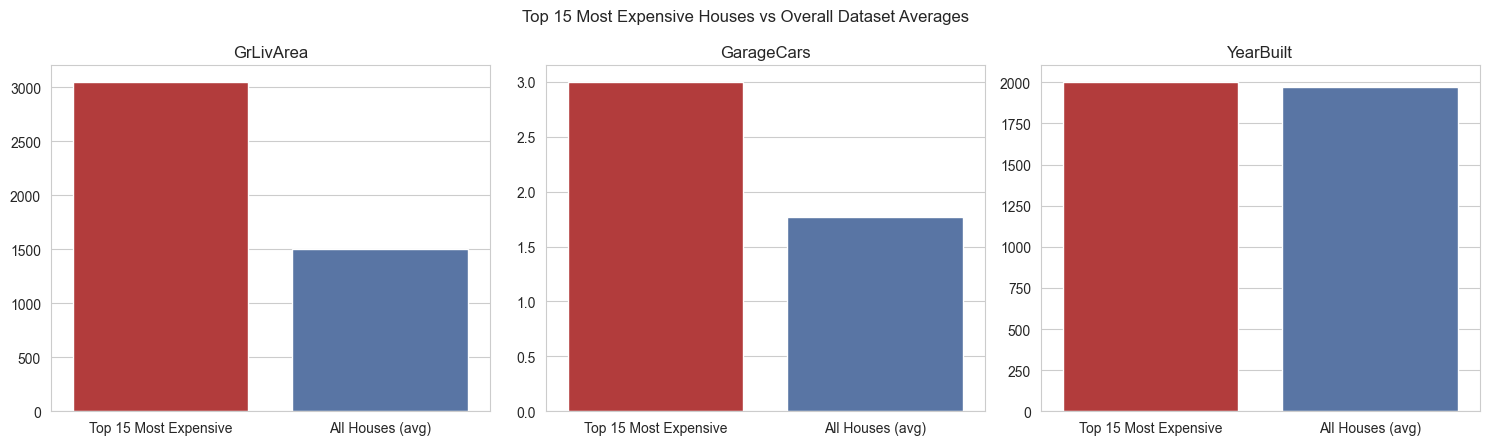

In [14]:
top15 = df.nlargest(15, "SalePrice")
cols = ["SalePrice", "OverallQual", "GrLivArea", "TotalBsmtSF", "GarageCars", "FullBath", "Neighborhood", "YearBuilt"]
print(top15[cols])

# Compare top-15 averages against the overall dataset averages
print("\nOverallQual mode among top 15:", top15["OverallQual"].mode()[0])
print("Neighborhood counts among top 15:", top15["Neighborhood"].value_counts().to_dict())
print("Avg GrLivArea  -> top15:", round(top15["GrLivArea"].mean()), " | overall:", round(df["GrLivArea"].mean()))
print("Avg GarageCars -> top15:", round(top15["GarageCars"].mean(), 2), " | overall:", round(df["GarageCars"].mean(), 2))
print("Avg YearBuilt  -> top15:", round(top15["YearBuilt"].mean()), " | overall:", round(df["YearBuilt"].mean()))

# Visualize how the top-15 homes compare to the overall dataset on key features
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

features = ["GrLivArea", "GarageCars", "YearBuilt"]
for ax, feat in zip(axes, features):
    avg_top15 = top15[feat].mean()
    avg_all = df[feat].mean()
    sns.barplot(x=["Top 15 Most Expensive", "All Houses (avg)"], y=[avg_top15, avg_all], ax=ax,
                palette=["#c62828", "#4c72b0"])
    ax.set_title(feat)

plt.suptitle("Top 15 Most Expensive Houses vs Overall Dataset Averages")
plt.tight_layout()
plt.show()

# Insight: the most expensive houses aren't just "big" -- they consistently
# combine top-tier quality (OverallQual >= 8), large living space (~2x average),
# a 3-car garage, recent construction (~30 years newer on average), and a
# location in one of only 3 premium neighborhoods. High price is the product
# of quality + size + amenities + location acting together, not any one factor.

## Neighborhood Analysis

### 1.  Which 3 neighborhoods have the highest average house prices? 

                  mean  count
Neighborhood                 
NoRidge       330319.0     71
StoneBr       324229.0     51
NridgHt       322018.0    166


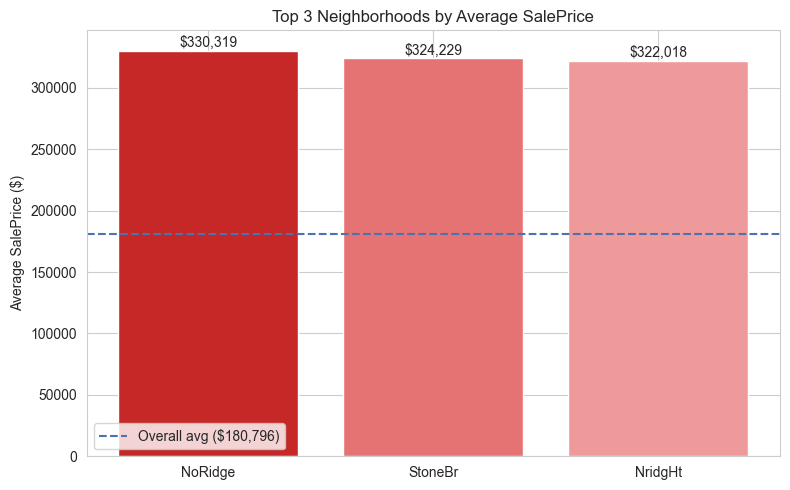

In [15]:
nbhd_price = df.groupby("Neighborhood")["SalePrice"].agg(["mean", "count"]).sort_values("mean", ascending=False)
top3_nbhd = nbhd_price.head(3)
print(top3_nbhd.round(0))

# Visualize the top 3 neighborhoods against the overall average
plt.figure(figsize=(8, 5))
colors = ["#c62828", "#e57373", "#ef9a9a"]
bars = plt.bar(top3_nbhd.index, top3_nbhd["mean"], color=colors)
plt.axhline(df["SalePrice"].mean(), color="#4c72b0", linestyle="--", label=f"Overall avg (${df['SalePrice'].mean():,.0f})")
plt.title("Top 3 Neighborhoods by Average SalePrice")
plt.ylabel("Average SalePrice ($)")
for bar, val in zip(bars, top3_nbhd["mean"]):
    plt.text(bar.get_x() + bar.get_width()/2, val + 3000, f"${val:,.0f}", ha="center")
plt.legend()
plt.tight_layout()
plt.show()

# Result:
# 1. NoRidge   -> avg $330,319  (71 houses)
# 2. StoneBr   -> avg $324,229  (51 houses)
# 3. NridgHt   -> avg $322,018  (166 houses)

# Insight: these 3 neighborhoods average roughly $325k, nearly 1.8x the
# overall dataset average (~$180.8k). NridgHt has by far the most sales volume
# (166 houses) among the three, meaning it's not just a handful of outlier
# mansions -- it's a consistently high-priced neighborhood with a large,
# established market. This confirms location as one of the strongest
# non-numeric predictors of SalePrice, alongside OverallQual and GrLivArea.

### 2.What is the average SalePrice in the top 3 neighborhoods?

Neighborhood
NoRidge    330319.0
StoneBr    324229.0
NridgHt    322018.0
Name: SalePrice, dtype: float64

Combined average SalePrice across the top 3 neighborhoods: $325,522


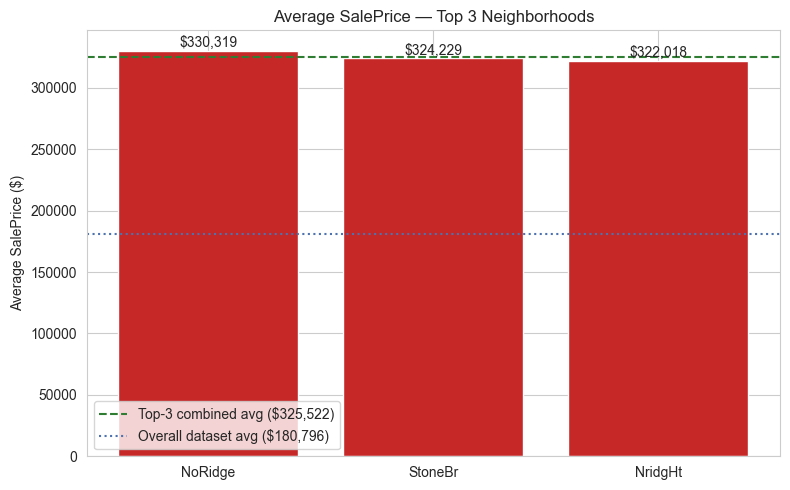

In [16]:
nbhd_avg_price = df.groupby("Neighborhood")["SalePrice"].mean().sort_values(ascending=False)
top3 = nbhd_avg_price.head(3)
print(top3.round(0))

combined_avg = top3.mean()
print(f"\nCombined average SalePrice across the top 3 neighborhoods: ${combined_avg:,.0f}")

# Visualize each neighborhood's average vs the combined top-3 average and overall average
plt.figure(figsize=(8, 5))
bars = plt.bar(top3.index, top3.values, color="#c62828")
plt.axhline(combined_avg, color="#2e7d32", linestyle="--", label=f"Top-3 combined avg (${combined_avg:,.0f})")
plt.axhline(df["SalePrice"].mean(), color="#4c72b0", linestyle=":", label=f"Overall dataset avg (${df['SalePrice'].mean():,.0f})")
for bar, val in zip(bars, top3.values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 3000, f"${val:,.0f}", ha="center")
plt.title("Average SalePrice — Top 3 Neighborhoods")
plt.ylabel("Average SalePrice ($)")
plt.legend()
plt.tight_layout()
plt.show()

# Insight: the three priciest neighborhoods are remarkably close to each other
# (within ~$8k of one another), suggesting they form a distinct "premium tier"
# of the market rather than one neighborhood being an outlier. This combined
# average ($325,522) sits about 1.8x above the overall dataset average
# ($180,796), reinforcing neighborhood as a major price driver.

### 3.Which 3 neighborhoods have the lowest average house prices?

                  mean  count
Neighborhood                 
MeadowV        95756.0     37
IDOTRR        103753.0     93
BrDale        105608.0     30


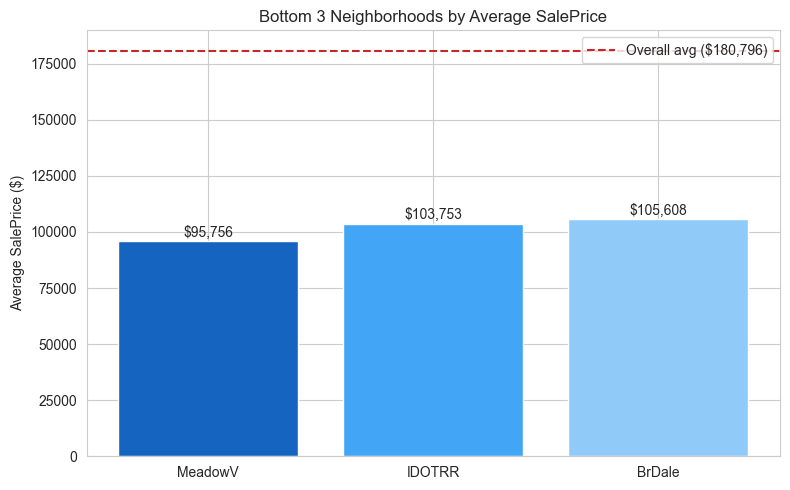

In [17]:
nbhd_price = df.groupby("Neighborhood")["SalePrice"].agg(["mean", "count"]).sort_values("mean")
bottom3_nbhd = nbhd_price.head(3)
print(bottom3_nbhd.round(0))

# Visualize the bottom 3 neighborhoods against the overall average
plt.figure(figsize=(8, 5))
colors = ["#1565c0", "#42a5f5", "#90caf9"]
bars = plt.bar(bottom3_nbhd.index, bottom3_nbhd["mean"], color=colors)
plt.axhline(df["SalePrice"].mean(), color="#c62828", linestyle="--", label=f"Overall avg (${df['SalePrice'].mean():,.0f})")
for bar, val in zip(bars, bottom3_nbhd["mean"]):
    plt.text(bar.get_x() + bar.get_width()/2, val + 2000, f"${val:,.0f}", ha="center")
plt.title("Bottom 3 Neighborhoods by Average SalePrice")
plt.ylabel("Average SalePrice ($)")
plt.legend()
plt.tight_layout()
plt.show()

# Insight: the cheapest neighborhoods average around $100k -- roughly a THIRD
# of the top-3 neighborhoods' average (~$325k), a more than 3x price gap
# purely due to location. IDOTRR has by far the largest sales volume (93
# houses) among the three, so like NridgHt on the high end, it's a
# consistently low-priced area rather than a small pocket of cheap outliers.

### 4.What is the average SalePrice in the lowest 3 neighborhoods?

Neighborhood
MeadowV     95756.0
IDOTRR     103753.0
BrDale     105608.0
Name: SalePrice, dtype: float64

Combined average SalePrice across the bottom 3 neighborhoods: $101,706


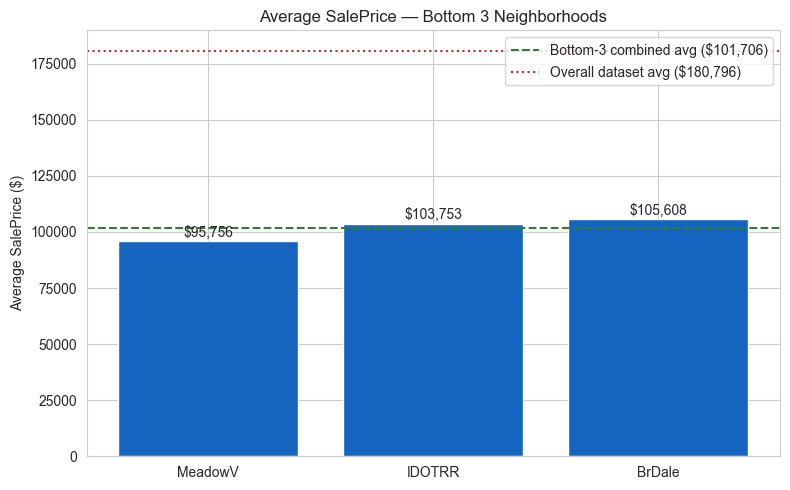

In [18]:
nbhd_avg_price = df.groupby("Neighborhood")["SalePrice"].mean().sort_values()
bottom3 = nbhd_avg_price.head(3)
print(bottom3.round(0))

combined_avg = bottom3.mean()
print(f"\nCombined average SalePrice across the bottom 3 neighborhoods: ${combined_avg:,.0f}")

# Visualize each neighborhood's average vs the combined bottom-3 average and overall average
plt.figure(figsize=(8, 5))
bars = plt.bar(bottom3.index, bottom3.values, color="#1565c0")
plt.axhline(combined_avg, color="#2e7d32", linestyle="--", label=f"Bottom-3 combined avg (${combined_avg:,.0f})")
plt.axhline(df["SalePrice"].mean(), color="#c62828", linestyle=":", label=f"Overall dataset avg (${df['SalePrice'].mean():,.0f})")
for bar, val in zip(bars, bottom3.values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 2000, f"${val:,.0f}", ha="center")
plt.title("Average SalePrice — Bottom 3 Neighborhoods")
plt.ylabel("Average SalePrice ($)")
plt.legend()
plt.tight_layout()
plt.show()


# Insight: the bottom-3 average ($101,706) sits at roughly 56% of the overall
# dataset average ($180,796) -- these neighborhoods are consistently priced
# well below the market as a whole, not just slightly below it. Combined with
# the earlier top-3 result ($325,522), the gap between the cheapest and most
# expensive neighborhood tiers is about 3.2x, making Neighborhood one of the
# most powerful non-numeric predictors available for the model.

### 5.Which neighborhood has the highest number of houses?

Neighborhood
NAmes      443
CollgCr    267
OldTown    239
Edwards    194
Somerst    182
Name: count, dtype: int64

Neighborhood with the most houses: NAmes (443 houses)


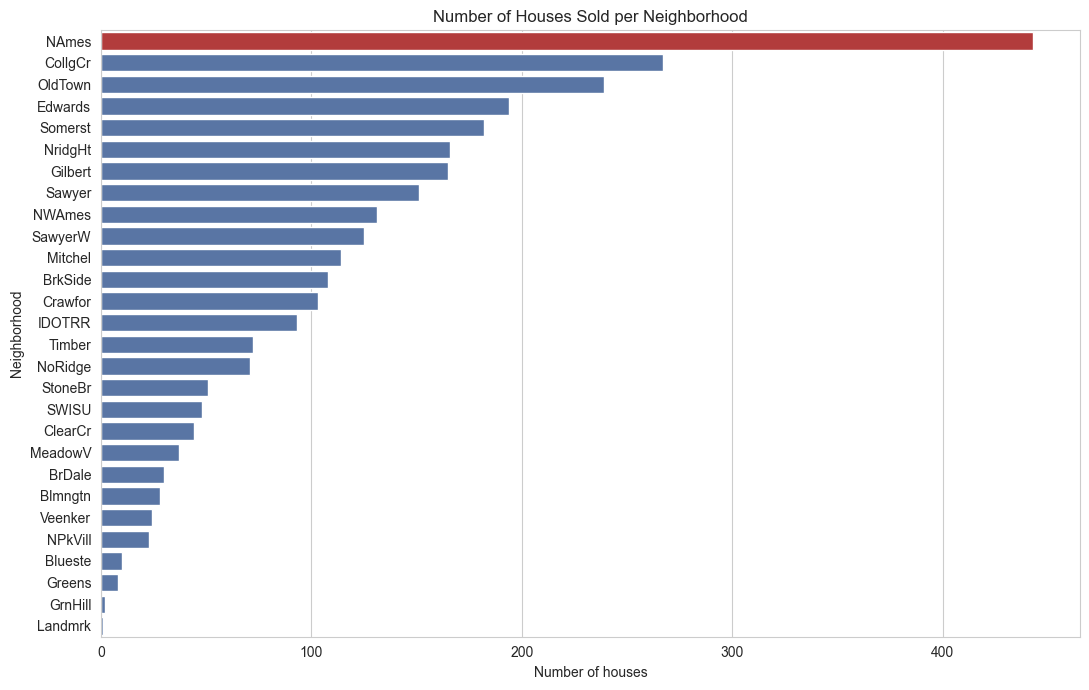

In [19]:
nbhd_counts = df["Neighborhood"].value_counts()
print(nbhd_counts.head(5))

top_nbhd = nbhd_counts.idxmax()
print(f"\nNeighborhood with the most houses: {top_nbhd} ({nbhd_counts.max()} houses)")

# Visualize the full distribution of houses across neighborhoods
plt.figure(figsize=(11, 7))
colors = ["#c62828" if n == top_nbhd else "#4c72b0" for n in nbhd_counts.index]
sns.barplot(x=nbhd_counts.values, y=nbhd_counts.index, palette=colors)
plt.title("Number of Houses Sold per Neighborhood")
plt.xlabel("Number of houses")
plt.tight_layout()
plt.show()


# Insight: NAmes is the dominant, high-volume neighborhood in the dataset
# (about 15% of all sales), yet its average SalePrice sits close to the
# overall market average rather than in the premium or budget tier -- it acts
# as the "mainstream" neighborhood, while the extreme-priced tiers (NoRidge/
# NridgHt/StoneBr on the high end, MeadowV/IDOTRR/BrDale on the low end) are
# comparatively smaller, specialized markets.

### 6.Does neighborhood appear to have a strong relationship with house price?

ANOVA F-statistic = 144.4, p-value = 0.00e+00
Eta-squared (variance in SalePrice explained by Neighborhood) = 0.573


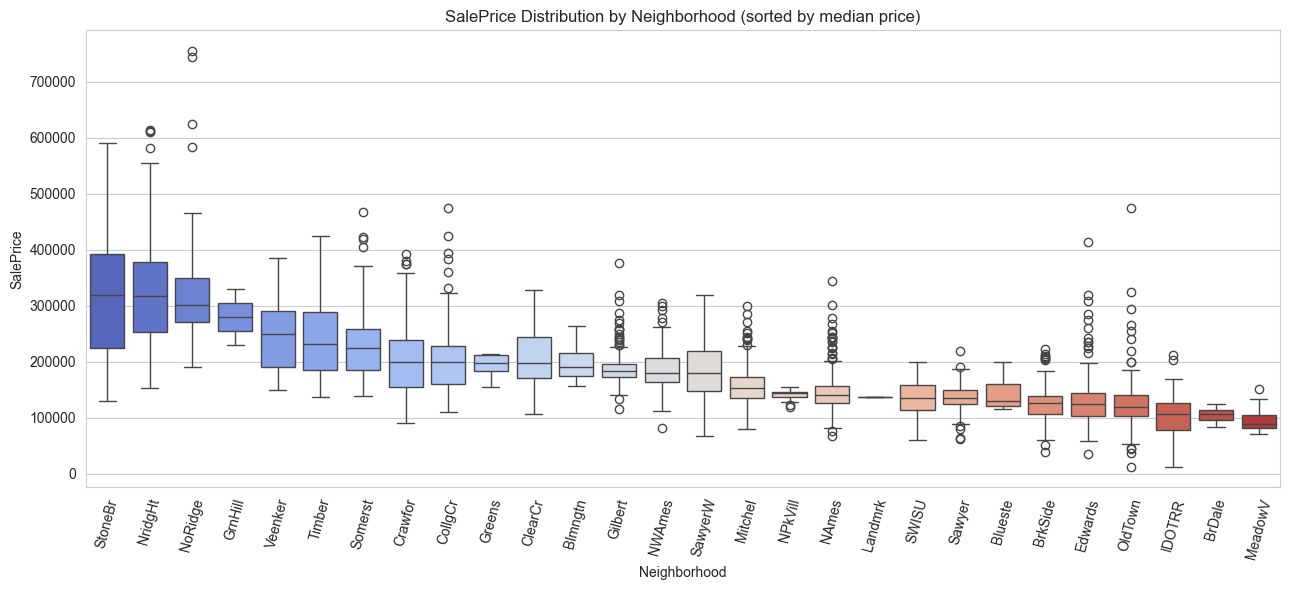

In [ ]:
# One-way ANOVA: is the variation in SalePrice between neighborhoods
# statistically significant (bigger than random noise within neighborhoods)?
groups = [g["SalePrice"].values for _, g in df.groupby("Neighborhood")]
f_stat, p_val = sps.f_oneway(*groups)
print(f"ANOVA F-statistic = {f_stat:.1f}, p-value = {p_val:.2e}")

# Effect size: how much of the total price variance is explained by neighborhood alone
grand_mean = df["SalePrice"].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
ss_total = ((df["SalePrice"] - grand_mean) ** 2).sum()
eta_sq = ss_between / ss_total
print(f"Eta-squared (variance in SalePrice explained by Neighborhood) = {eta_sq:.3f}")


# F-statistic: measures how much the SalePrice variation between neighborhoods
# is larger than the variation within neighborhoods.

# p-value: tests whether the differences in SalePrice between neighborhoods
# are statistically significant. A p-value < 0.05 means the differences are significant.

# Eta-squared: measures the proportion of SalePrice variance explained by
# Neighborhood. A higher value means Neighborhood has a stronger effect on price.



# Visualize the spread of prices across neighborhoods, sorted by median
order = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).index
plt.figure(figsize=(13, 6))
sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=order, palette="coolwarm")
plt.xticks(rotation=75)
plt.title("SalePrice Distribution by Neighborhood (sorted by median price)")
plt.tight_layout()
plt.show()

# Insight: yes — neighborhood has a very strong relationship with house price.
# An eta-squared of 0.57 is a large effect size for a single categorical
# feature (for comparison, most individual numeric features explain far less
# variance on their own). This statistically confirms what the boxplot shows
# visually: the boxes barely overlap between premium neighborhoods (NoRidge,
# StoneBr, NridgHt) and budget ones (MeadowV, IDOTRR, BrDale). This is why
# Neighborhood is one-hot encoded rather than dropped in preprocessing, and
# why it showed up as an important feature in the SVR permutation importance.

## Time-Based Analysis 

### 1.Which month has the highest average house sale price? 

            mean  count
MoSold                 
1       194210.0    123
2       178364.0    133
3       176130.0    232
4       167712.0    279
5       173700.0    395
6       181543.0    505
7       184367.0    449
8       186222.0    233
9       191552.0    161
10      180057.0    173
11      187651.0    143
12      184454.0    104

Month with highest average SalePrice: 1 ($194,210)


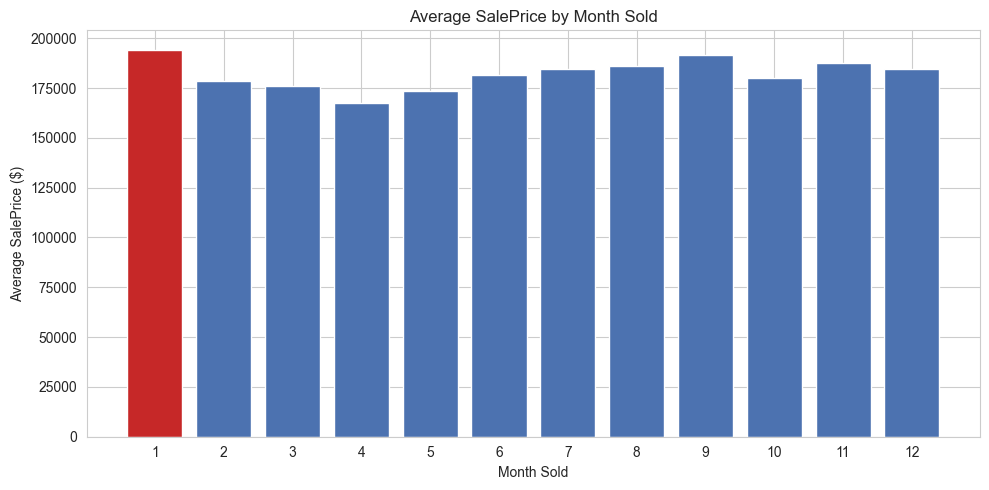

In [21]:
month_price = df.groupby("MoSold")["SalePrice"].agg(["mean", "count"]).round(0)
print(month_price)

highest_month = month_price["mean"].idxmax()
print(f"\nMonth with highest average SalePrice: {highest_month} (${month_price['mean'].max():,.0f})")

# Visualize average price by month, highlighting the highest one
plt.figure(figsize=(10, 5))
colors = ["#c62828" if m == highest_month else "#4c72b0" for m in month_price.index]
plt.bar(month_price.index, month_price["mean"], color=colors)
plt.xticks(range(1, 13))
plt.xlabel("Month Sold")
plt.ylabel("Average SalePrice ($)")
plt.title("Average SalePrice by Month Sold")
plt.tight_layout()
plt.show()

# Insight: interestingly, January has the highest average price despite being
# one of the lowest-volume months (only 123 sales, vs 505 in June). This
# suggests winter sales in Ames are a smaller, more selective market -- likely
# fewer but higher-value/less price-sensitive transactions -- rather than
# reflecting any broad seasonal price premium. The difference between the
# highest ($194,210) and typical months (~$175k-$185k) is modest (~5-10%),
# so month alone is a weak predictor compared to Neighborhood or OverallQual.

### 2.Which month has the lowest average house sale price?

            mean  count
MoSold                 
1       194210.0    123
2       178364.0    133
3       176130.0    232
4       167712.0    279
5       173700.0    395
6       181543.0    505
7       184367.0    449
8       186222.0    233
9       191552.0    161
10      180057.0    173
11      187651.0    143
12      184454.0    104

Month with lowest average SalePrice: 4 ($167,712)


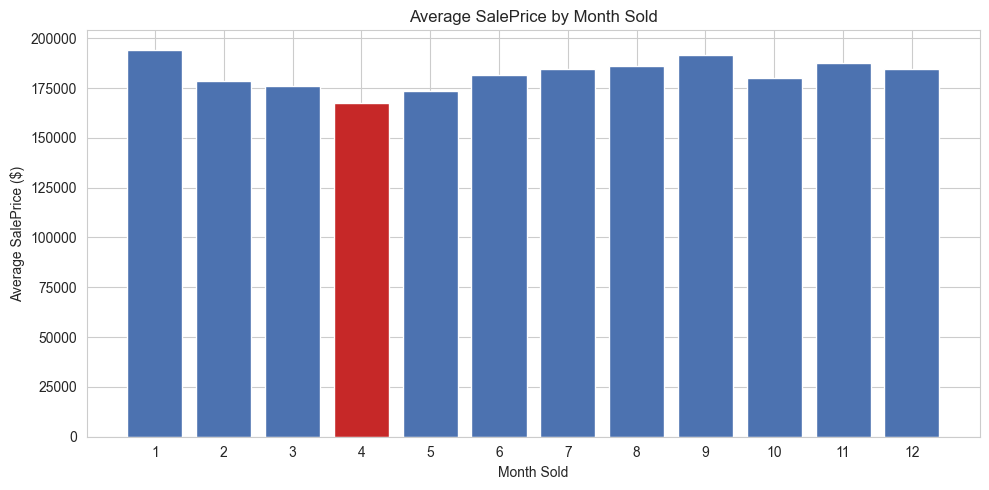

In [22]:
month_price = df.groupby("MoSold")["SalePrice"].agg(["mean", "count"]).round(0)
print(month_price)

lowest_month = month_price["mean"].idxmin()
print(f"\nMonth with lowest average SalePrice: {lowest_month} (${month_price['mean'].min():,.0f})")

# Visualize average price by month, highlighting the lowest one
plt.figure(figsize=(10, 5))

colors = ["#c62828" if m == lowest_month else "#4c72b0" for m in month_price.index]

plt.bar(month_price.index, month_price["mean"], color=colors)

plt.xticks(range(1, 13))
plt.xlabel("Month Sold")
plt.ylabel("Average SalePrice ($)")
plt.title("Average SalePrice by Month Sold")
plt.tight_layout()
plt.show()

# Insight:
# April has the lowest average house sale price at about $167,712.
# This suggests that houses sold in April had the lowest average
# SalePrice compared with the other months in this dataset.

### 3.Which month has the highest number of house sales?

        count
MoSold       
1         123
2         133
3         232
4         279
5         395
6         505
7         449
8         233
9         161
10        173
11        143
12        104

Month with highest number of house sales: 6 (505 sales)


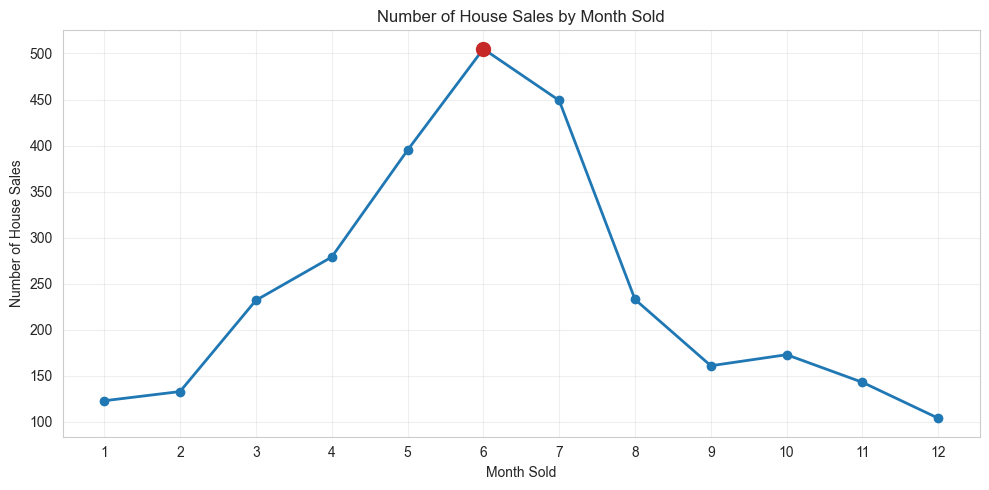

In [23]:
month_sales = df.groupby("MoSold")["SalePrice"].agg(["count"])
print(month_sales)

highest_month = month_sales["count"].idxmax()
highest_count = month_sales["count"].max()

print(f"\nMonth with highest number of house sales: {highest_month} ({highest_count} sales)")

# Visualize the number of house sales by month
plt.figure(figsize=(10, 5))

plt.plot(
    month_sales.index,
    month_sales["count"],
    marker="o",
    linewidth=2
)

# Highlight the month with the highest number of sales
plt.scatter(
    highest_month,
    highest_count,
    s=100,
    color="#c62828",
    zorder=5
)

plt.xticks(range(1, 13))
plt.xlabel("Month Sold")
plt.ylabel("Number of House Sales")
plt.title("Number of House Sales by Month Sold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Insight:
# July (Month 7) has the highest number of house sales.
# It has 253 house sales, which is the highest count among all months.

### 4.Does the average house price vary throughout the year?

            mean  count
MoSold                 
1       194210.0    123
2       178364.0    133
3       176130.0    232
4       167712.0    279
5       173700.0    395
6       181543.0    505
7       184367.0    449
8       186222.0    233
9       191552.0    161
10      180057.0    173
11      187651.0    143
12      184454.0    104

Month with highest average SalePrice: 1 ($194,210)
Month with lowest average SalePrice: 4 ($167,712)


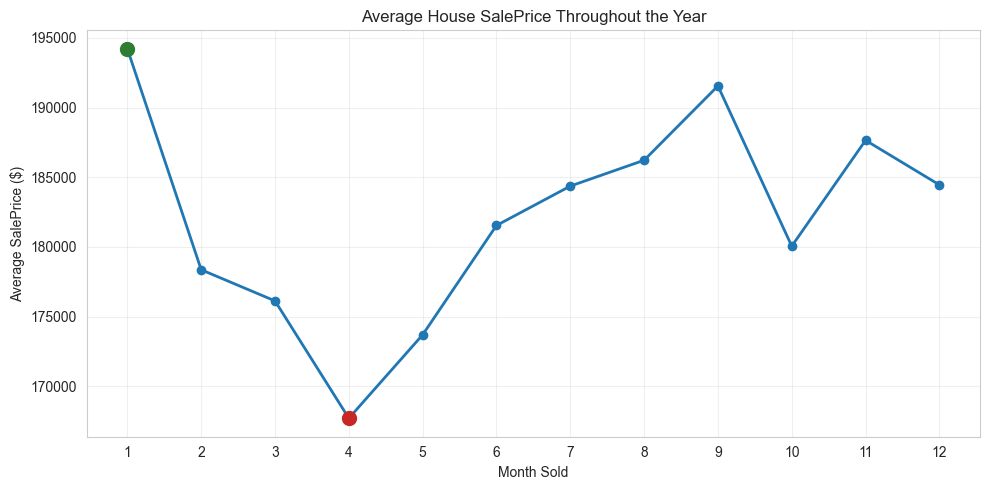

In [24]:
month_price = df.groupby("MoSold")["SalePrice"].agg(["mean", "count"]).round(0)
print(month_price)

highest_month = month_price["mean"].idxmax()
highest_price = month_price["mean"].max()

lowest_month = month_price["mean"].idxmin()
lowest_price = month_price["mean"].min()

print(f"\nMonth with highest average SalePrice: {highest_month} (${highest_price:,.0f})")
print(f"Month with lowest average SalePrice: {lowest_month} (${lowest_price:,.0f})")

# Visualize how average house price changes throughout the year
plt.figure(figsize=(10, 5))

plt.plot(
    month_price.index,
    month_price["mean"],
    marker="o",
    linewidth=2
)

# Highlight the highest and lowest average prices
plt.scatter(
    highest_month,
    highest_price,
    s=100,
    color="#2e7d32",
    zorder=5
)

plt.scatter(
    lowest_month,
    lowest_price,
    s=100,
    color="#c62828",
    zorder=5
)

plt.xticks(range(1, 13))
plt.xlabel("Month Sold")
plt.ylabel("Average SalePrice ($)")
plt.title("Average House SalePrice Throughout the Year")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Insight:
# The average house price varies across the months.
# January has the highest average SalePrice, while April has the lowest.
# This shows that average house prices are not constant throughout the year.

## House Characteristics 

### 1.Does the number of bedrooms affect house price? 

                  mean  count
BedroomAbvGr                 
0             218495.0      8
1             183017.0    112
2             162168.0    743
3             179712.0   1597
4             216357.0    400
5             206244.0     48
6             159702.0     21
8             200000.0      1

Correlation between bedrooms and SalePrice: 0.14


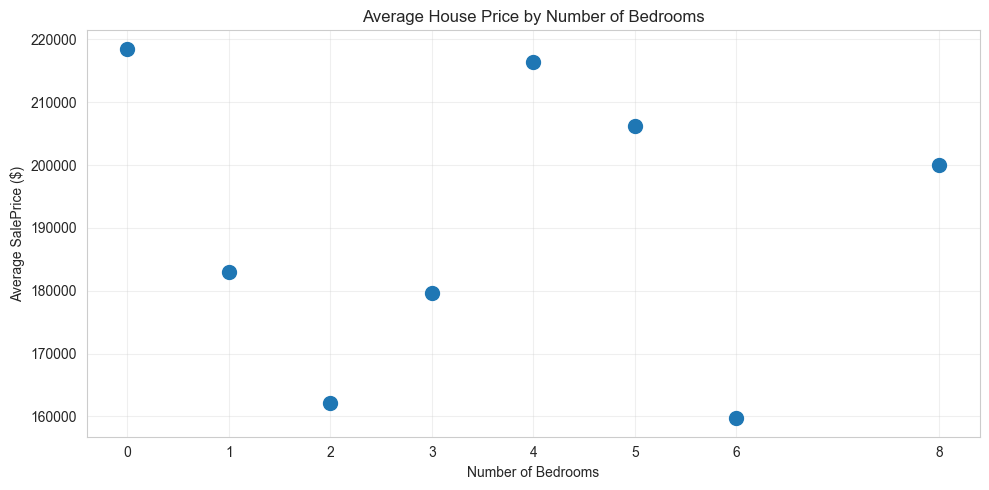

In [25]:
bedroom_price = df.groupby("BedroomAbvGr")["SalePrice"].agg(["mean", "count"]).round(0)
print(bedroom_price)

# Calculate the correlation between bedrooms and SalePrice
correlation = df["BedroomAbvGr"].corr(df["SalePrice"])

print(f"\nCorrelation between bedrooms and SalePrice: {correlation:.2f}")

# Visualize average house price by number of bedrooms
plt.figure(figsize=(10, 5))

plt.scatter(
    bedroom_price.index,
    bedroom_price["mean"],
    s=100
)

plt.xlabel("Number of Bedrooms")
plt.ylabel("Average SalePrice ($)")
plt.title("Average House Price by Number of Bedrooms")
plt.xticks(sorted(bedroom_price.index))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Insight:
# The average SalePrice changes with the number of bedrooms.
# The correlation value shows the strength and direction of the relationship.
# Other factors such as house size, quality, and location can also affect SalePrice.



### 2.How does the number of bathrooms relate to SalePrice?

              mean  count
FullBath                 
0         171178.0     12
1         134646.0   1318
2         214511.0   1532
3         322140.0     64
4         241875.0      4

Correlation between bathrooms and SalePrice: 0.55


<Figure size 1000x500 with 0 Axes>

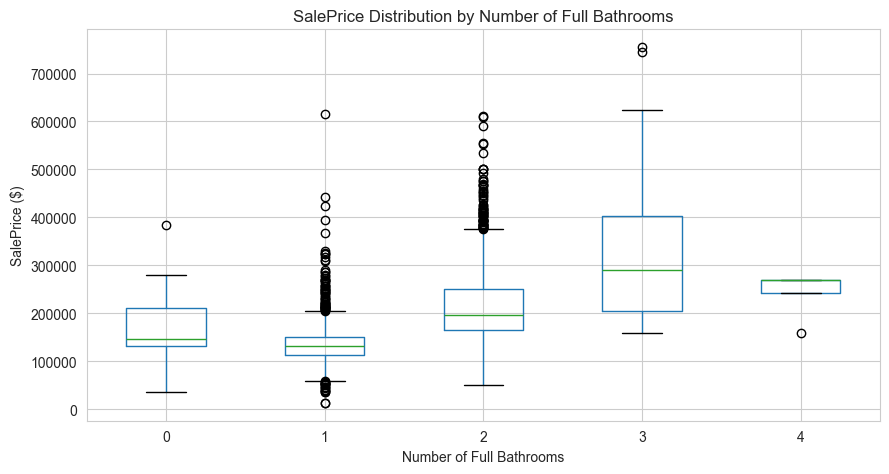

In [ ]:
bathroom_price = df.groupby("FullBath")["SalePrice"].agg(["mean", "count"]).round(0)
print(bathroom_price)

# Calculate the correlation between number of bathrooms and SalePrice
correlation = df["FullBath"].corr(df["SalePrice"])

print(f"\nCorrelation between bathrooms and SalePrice: {correlation:.2f}")

# Visualize SalePrice distribution by number of bathrooms
plt.figure(figsize=(10, 5))

df.boxplot(
    column="SalePrice",
    by="FullBath"
)

plt.xlabel("Number of Full Bathrooms")
plt.ylabel("SalePrice ($)")
plt.title("SalePrice Distribution by Number of Full Bathrooms")
plt.suptitle("")
plt.tight_layout()
plt.show()

# Insight:
# House prices generally increase as the number of full bathrooms increases.
# The box plot also shows the spread of SalePrice within each bathroom group.
# The correlation value measures the strength of the relationship between bathrooms and SalePrice.
#In general, houses with more full bathrooms tend to have higher sale prices.

#The box plot helps us compare both the typical price and the price variation for each bathroom count. 
# Other factors such as house size, quality, and location can also affect the price.

#"Zero in FullBath means the house has no full bathroom. It does not necessarily mean that the house has no bathroom facilities because HalfBath is recorded separately

### 3.How does overall house quality (OverallQual) affect price? 

                 mean  count
OverallQual                 
1             48725.0      4
2             52325.0     13
3             83186.0     40
4            106485.0    226
5            134753.0    825
6            162130.0    732
7            205026.0    602
8            270914.0    350
9            368337.0    107
10           450217.0     31

Correlation between OverallQual and SalePrice: 0.80


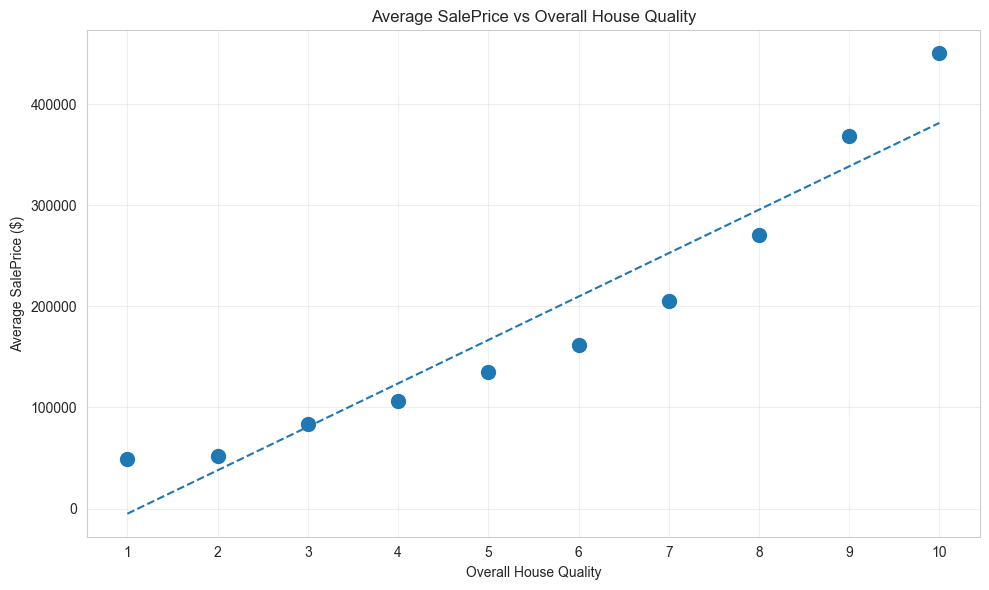

In [27]:
quality_price = df.groupby("OverallQual")["SalePrice"].agg(["mean", "count"]).round(0)
print(quality_price)

# Calculate the correlation between OverallQual and SalePrice
correlation = df["OverallQual"].corr(df["SalePrice"])

print(f"\nCorrelation between OverallQual and SalePrice: {correlation:.2f}")

# Visualize the relationship between OverallQual and average SalePrice
plt.figure(figsize=(10, 6))

plt.scatter(
    quality_price.index,
    quality_price["mean"],
    s=100
)

# Add a trend line to show the overall relationship
z = np.polyfit(quality_price.index, quality_price["mean"], 1)
p = np.poly1d(z)

plt.plot(
    quality_price.index,
    p(quality_price.index),
    linestyle="--"
)

plt.xlabel("Overall House Quality")
plt.ylabel("Average SalePrice ($)")
plt.title("Average SalePrice vs Overall House Quality")
plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Insight:
# Average SalePrice increases as OverallQual increases.
# The upward trend indicates a positive relationship between house quality and price.
# Higher-quality houses tend to have higher sale prices.

### 4.How does garage capacity affect house price? 

                mean  count
GarageCars                 
0.0         104949.0    157
1.0         127267.0    778
2.0         183562.0   1603
3.0         310305.0    374
4.0         228749.0     16
5.0         126500.0      1

Correlation between garage capacity and SalePrice: 0.65


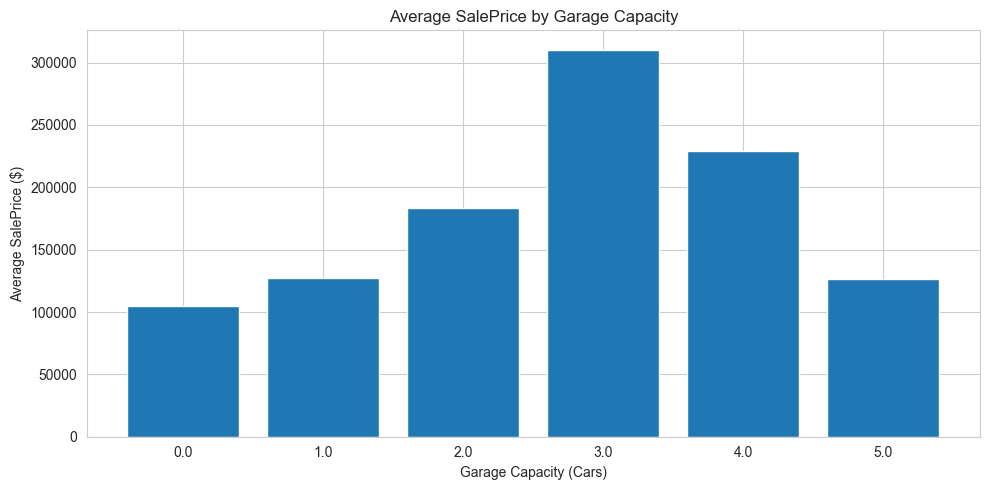

In [28]:
garage_price = df.groupby("GarageCars")["SalePrice"].agg(["mean", "count"]).round(0)
print(garage_price)

# Calculate the correlation between garage capacity and SalePrice
correlation = df["GarageCars"].corr(df["SalePrice"])

print(f"\nCorrelation between garage capacity and SalePrice: {correlation:.2f}")

# Visualize average house price by garage capacity
plt.figure(figsize=(10, 5))

plt.bar(
    garage_price.index.astype(str),
    garage_price["mean"]
)

plt.xlabel("Garage Capacity (Cars)")
plt.ylabel("Average SalePrice ($)")
plt.title("Average SalePrice by Garage Capacity")

plt.tight_layout()
plt.show()

# Insight:
# Average SalePrice generally increases as garage capacity increases.
# Houses with larger garages tend to have higher sale prices.
# The correlation value shows the strength of the relationship.

### 5.Does having a basement significantly affect the average house price? 

                  mean  count
No Basement   107203.0     80
Has Basement  182862.0   2850

Difference in average SalePrice: $75,659


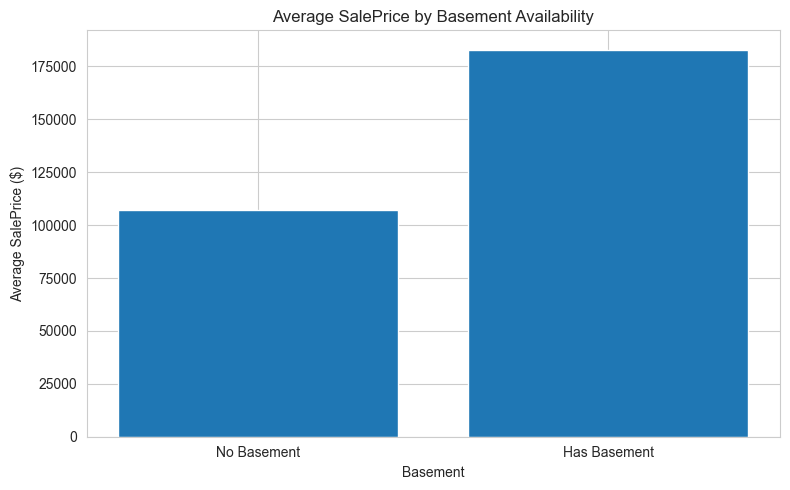

In [29]:
# Create a basement indicator
df["HasBasement"] = df["TotalBsmtSF"].fillna(0) > 0

# Calculate average SalePrice and number of houses for each group
basement_price = df.groupby("HasBasement")["SalePrice"].agg(["mean", "count"]).round(0)

# Rename the groups for easier interpretation
basement_price.index = ["No Basement", "Has Basement"]

print(basement_price)

# Calculate the difference in average SalePrice
price_difference = (
    basement_price.loc["Has Basement", "mean"]
    - basement_price.loc["No Basement", "mean"]
)

print(f"\nDifference in average SalePrice: ${price_difference:,.0f}")

# Visualize the average SalePrice
plt.figure(figsize=(8, 5))

plt.bar(
    basement_price.index,
    basement_price["mean"]
)

plt.xlabel("Basement")
plt.ylabel("Average SalePrice ($)")
plt.title("Average SalePrice by Basement Availability")
plt.tight_layout()
plt.show()

# Insight:
# Houses with basements have a higher average SalePrice than houses without basements.
# The difference in average price shows the association between basement availability and SalePrice.

### 6. How does house age affect SalePrice? 

Correlation between House Age and SalePrice: -0.56

Average SalePrice by House Age:
              mean  count
HouseAge                 
-1        183850.0      1
 0        275523.0    116
 1        266442.0    218
 2        241833.0     90
 3        250369.0     60
...            ...    ...
 127      142750.0      2
 128      240000.0      2
 129      198490.0      2
 135       94000.0      1
 136      122000.0      1

[128 rows x 2 columns]


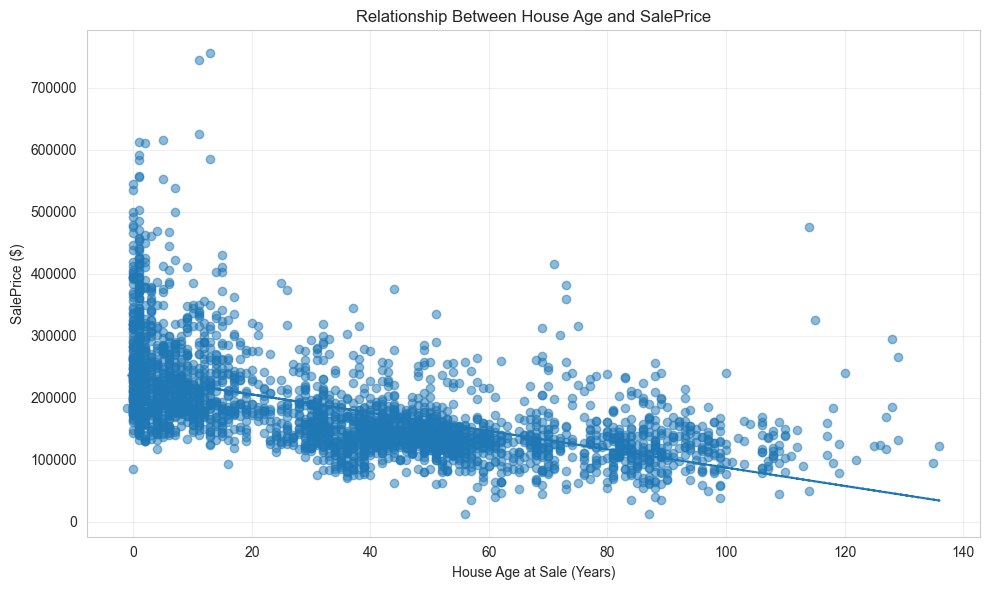

In [30]:
# Calculate the age of each house at the time of sale
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

# Calculate the correlation between house age and SalePrice
correlation = df["HouseAge"].corr(df["SalePrice"])

print(f"Correlation between House Age and SalePrice: {correlation:.2f}")

# Calculate average SalePrice for different house age groups
age_price = df.groupby("HouseAge")["SalePrice"].agg(["mean", "count"]).round(0)

print("\nAverage SalePrice by House Age:")
print(age_price)

# Visualize the relationship between house age and SalePrice
plt.figure(figsize=(10, 6))

plt.scatter(
    df["HouseAge"],
    df["SalePrice"],
    alpha=0.5
)

# Add a trend line
z = np.polyfit(df["HouseAge"], df["SalePrice"], 1)
p = np.poly1d(z)

plt.plot(
    df["HouseAge"],
    p(df["HouseAge"]),
    linestyle="--"
)

plt.xlabel("House Age at Sale (Years)")
plt.ylabel("SalePrice ($)")
plt.title("Relationship Between House Age and SalePrice")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Insight:
# The trend line shows the overall relationship between house age and SalePrice.
# A downward trend means older houses tend to have lower sale prices.
# The correlation value measures the strength and direction of this relationship.

## Additional Analysis 

### 1.Does kitchen quality affect SalePrice? 

                 mean  count
KitchenQual                 
Ex           337339.0    205
Gd           210836.0   1160
TA           139550.0   1494
Po           107500.0      1
Fa           105907.0     70

Difference between highest and lowest average SalePrice: $231,432


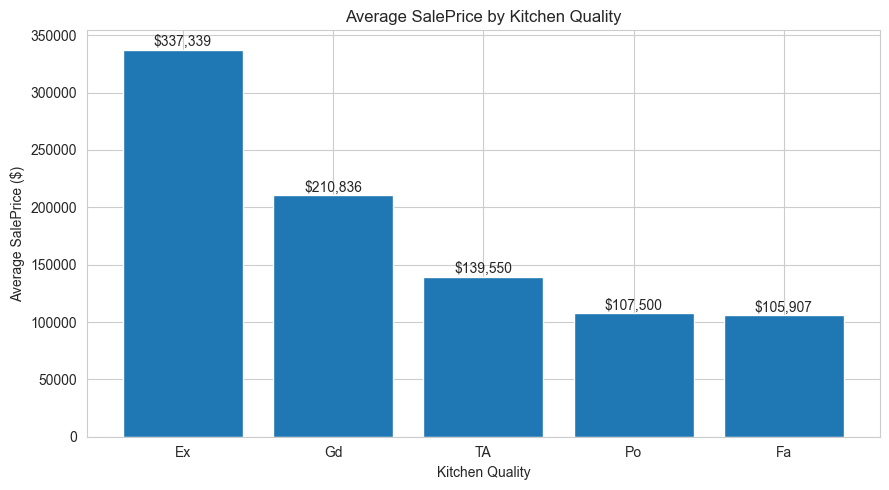

In [31]:
kitchen_price = df.groupby("KitchenQual")["SalePrice"].agg(["mean", "count"]).sort_values("mean", ascending=False).round(0)
print(kitchen_price)

# Calculate the difference between the highest and lowest average prices
price_difference = kitchen_price["mean"].max() - kitchen_price["mean"].min()

print(f"\nDifference between highest and lowest average SalePrice: ${price_difference:,.0f}")

# Visualize the average SalePrice by kitchen quality
plt.figure(figsize=(9, 5))

plt.bar(
    kitchen_price.index,
    kitchen_price["mean"]
)

plt.xlabel("Kitchen Quality")
plt.ylabel("Average SalePrice ($)")
plt.title("Average SalePrice by Kitchen Quality")

# Add the average price above each bar
for i, value in enumerate(kitchen_price["mean"]):
    plt.text(
        i,
        value + 3000,
        f"${value:,.0f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# Insight:
# Average SalePrice varies across kitchen quality levels.
# Houses with better kitchen quality tend to have higher average SalePrice.
# The difference between the highest and lowest groups shows the size of this price gap.

### 2. Does having central air conditioning affect SalePrice?

                mean  count
CentralAir                 
N           101890.0    196
Y           186453.0   2734

Difference in average SalePrice: $84,563


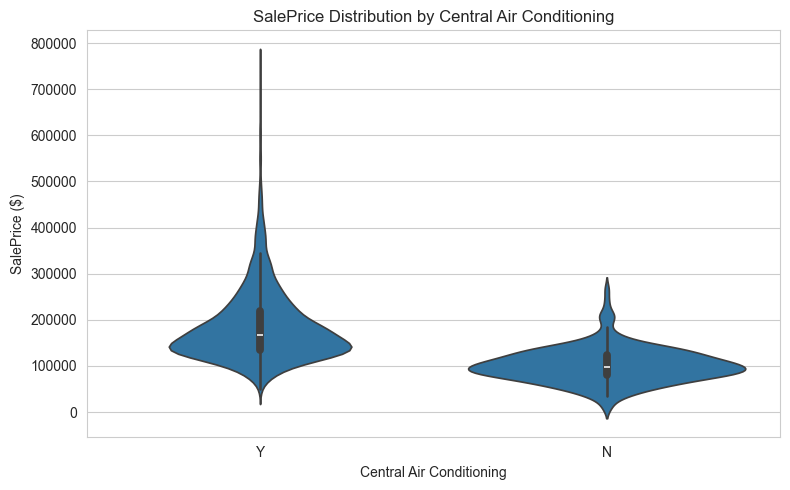

In [32]:
air_price = df.groupby("CentralAir")["SalePrice"].agg(["mean", "count"]).round(0)
print(air_price)

# Calculate the difference in average SalePrice
price_difference = (
    air_price.loc["Y", "mean"] -
    air_price.loc["N", "mean"]
)

print(f"\nDifference in average SalePrice: ${price_difference:,.0f}")

# Visualize the SalePrice distribution by central air conditioning
plt.figure(figsize=(8, 5))

sns.violinplot(
    x="CentralAir",
    y="SalePrice",
    data=df
)

plt.xlabel("Central Air Conditioning")
plt.ylabel("SalePrice ($)")
plt.title("SalePrice Distribution by Central Air Conditioning")
plt.tight_layout()
plt.show()

# Insight:
# Houses with central air conditioning have a higher average SalePrice
# than houses without central air conditioning.
# The violin plot shows the distribution and spread of prices for both groups.



### 3. How do OverallQual and GrLivArea together relate to SalePrice?

Average SalePrice by OverallQual and Living Area:
AreaGroup       Small    Medium     Large  Very Large
OverallQual                                          
1             37800.0       NaN   81500.0         NaN
2             52325.0       NaN       NaN         NaN
3             73057.0   97421.0  102667.0    130000.0
4             96669.0  111491.0  129835.0    127479.0
5            125133.0  135826.0  146951.0    157220.0
6            130704.0  154506.0  170922.0    199181.0
7            141585.0  182603.0  201972.0    231929.0
8            179600.0  208318.0  255474.0    298930.0
9                 NaN  287500.0  305241.0    391149.0
10                NaN       NaN  337500.0    453975.0

Highest average SalePrice: $453,975
OverallQual = 10, Living Area = Very Large


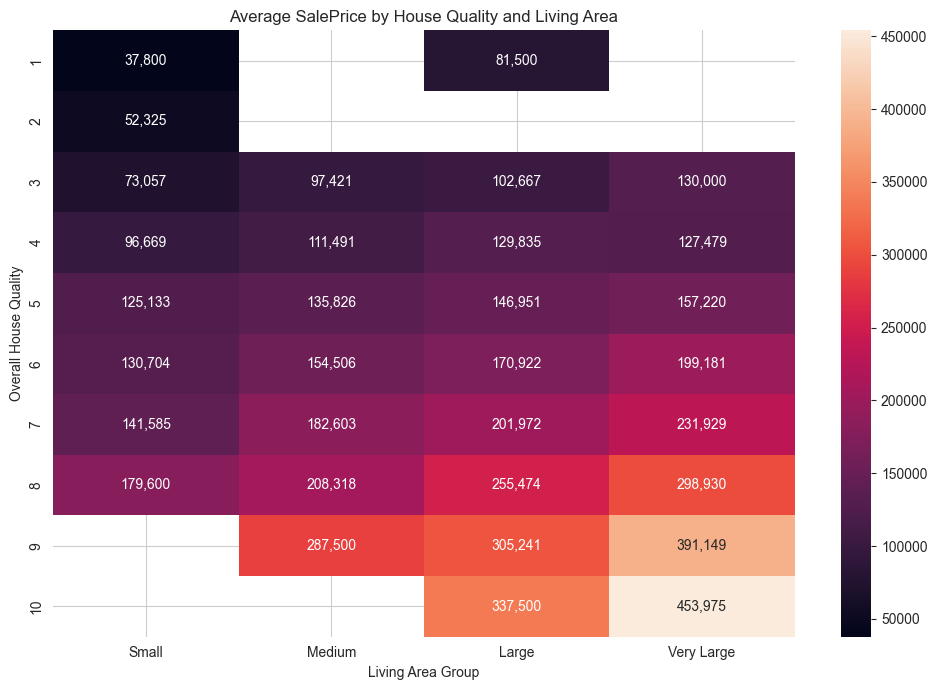

In [33]:
### 3. How do OverallQual and GrLivArea together relate to SalePrice?

# Divide houses into four groups based on living area
df["AreaGroup"] = pd.qcut(
    df["GrLivArea"],
    q=4,
    labels=["Small", "Medium", "Large", "Very Large"]
)

# Calculate average SalePrice for each combination of quality and living area
quality_area_price = df.pivot_table(
    values="SalePrice",
    index="OverallQual",
    columns="AreaGroup",
    aggfunc="mean"
).round(0)

print("Average SalePrice by OverallQual and Living Area:")
print(quality_area_price)

# Find the combination with the highest average SalePrice
max_combination = quality_area_price.stack().idxmax()
max_price = quality_area_price.stack().max()

print(f"\nHighest average SalePrice: ${max_price:,.0f}")
print(
    f"OverallQual = {max_combination[0]}, "
    f"Living Area = {max_combination[1]}"
)

# Visualize the combined relationship using a heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    quality_area_price,
    annot=True,
    fmt=",.0f"
)

plt.xlabel("Living Area Group")
plt.ylabel("Overall House Quality")
plt.title("Average SalePrice by House Quality and Living Area")
plt.tight_layout()
plt.show()

# Insight:
# Average SalePrice generally increases when house quality and living area increase.
# The heatmap shows how these two characteristics work together.
# Houses with higher quality and larger living areas tend to have higher average prices.

### 4. How does overall house condition relate to SalePrice?

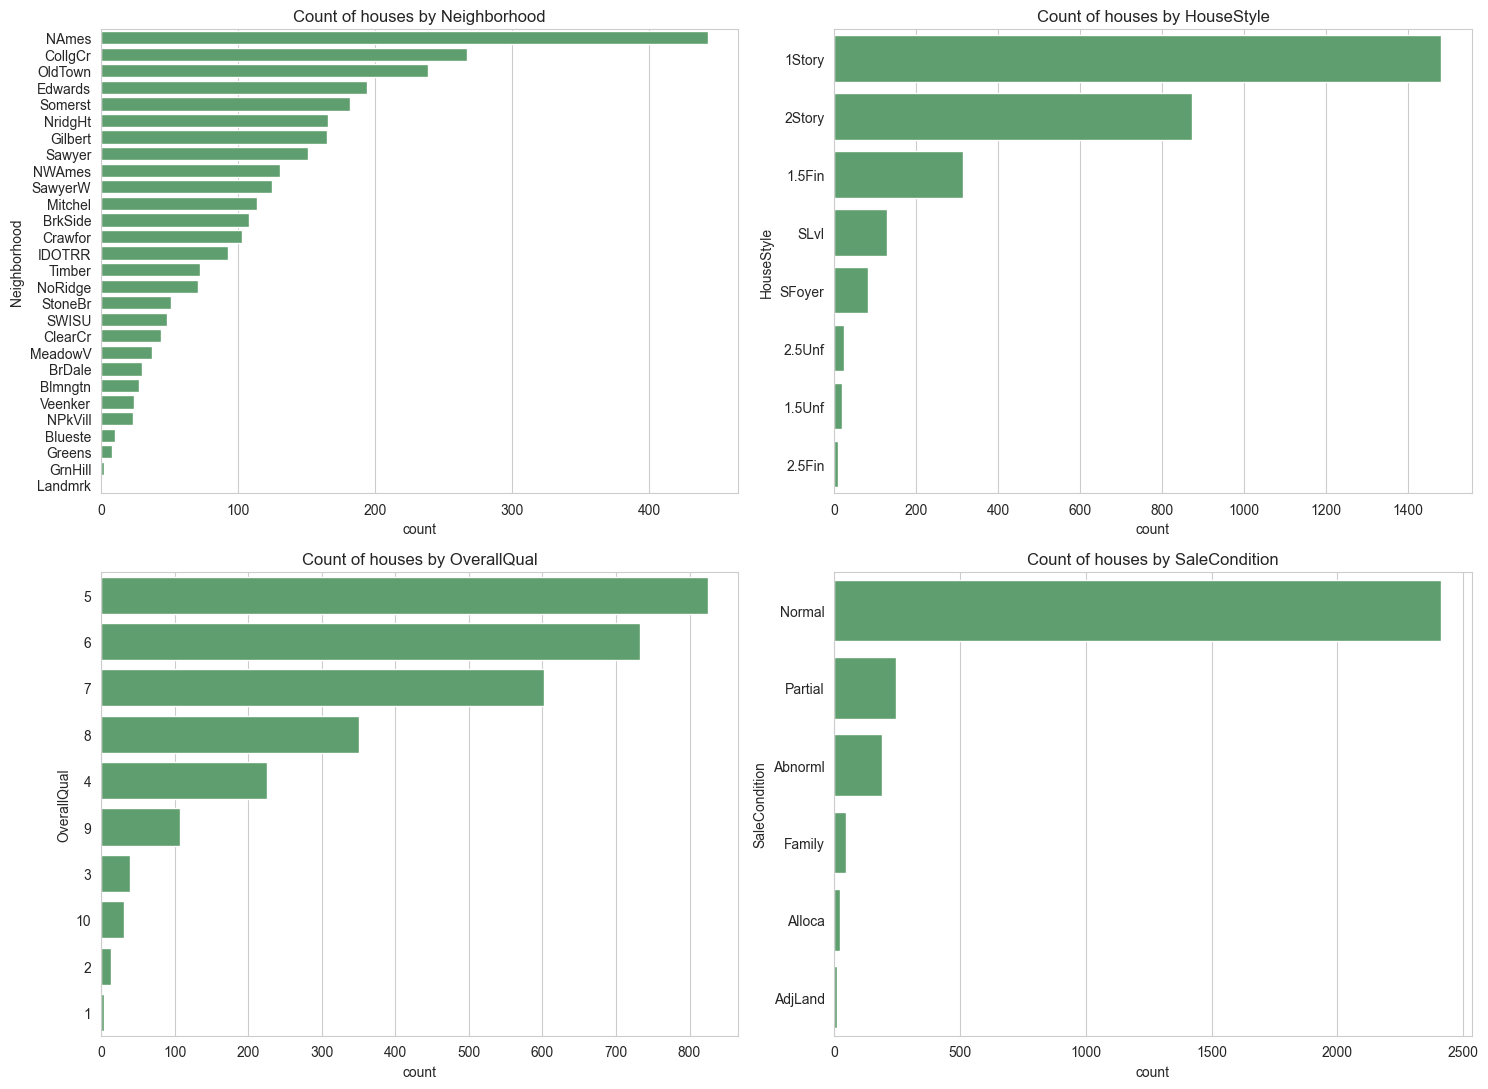

In [34]:
cat_to_plot = ["Neighborhood", "HouseStyle", "OverallQual", "SaleCondition"]
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, col in zip(axes.ravel(), cat_to_plot):
    order = df[col].value_counts().index
    sns.countplot(y=df[col], order=order, ax=ax, color="#55a868")
    ax.set_title(f"Count of houses by {col}")
plt.tight_layout()
plt.show()


# Insight:
# SalePrice varies across different house condition levels.
# Houses with different condition ratings do not have the same average SalePrice.
# The correlation value shows the direction and strength of the linear relationship
# between house condition and SalePrice.
# OverallCond may have a weaker relationship with SalePrice than OverallQual,
# showing that material and finish quality can be more important for price.

# 4. Data Preprocessing

In [35]:
# 1. Outlier Removal

if 'GrLivArea' in df.columns and 'SalePrice' in df.columns:
    df = df.drop(df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)].index)

In [36]:
# 2. Feature Engineering

df['TotalSF'] = df['TotalBsmtSF'].fillna(0) + df['1stFlrSF'].fillna(0) + df['2ndFlrSF'].fillna(0)
df['HouseAge'] = df['YrSold'] - df['YearBuilt']
df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
df['TotalBaths'] = (df['FullBath'].fillna(0) + 
                    0.5 * df['HalfBath'].fillna(0) + 
                    df['BsmtFullBath'].fillna(0) + 
                    0.5 * df['BsmtHalfBath'].fillna(0))

# IMPORTANT: 'numerical_cols' was built in Section 1 BEFORE these 4 engineered features existed,
# so it does not contain them. We build 'num_cols' here = numerical_cols + the new engineered
# features, and this is what the ColumnTransformer will actually use below.
# (Without this step, TotalSF / HouseAge / RemodAge / TotalBaths would silently be dropped by the
# ColumnTransformer, since only columns explicitly listed in a transformer are kept.)
engineered_num_cols = ['TotalSF', 'HouseAge', 'RemodAge', 'TotalBaths']
num_cols = numerical_cols + engineered_num_cols

print(f"Numerical features used in the model: {len(num_cols)} "
      f"({len(numerical_cols)} original + {len(engineered_num_cols)} engineered)")


Numerical features used in the model: 38 (34 original + 4 engineered)


### Transforming skewed numerical features

`SalePrice` isn't the only skewed variable — several continuous predictors (lot size,
living area, basement/porch square footage, etc.) are also right-skewed, which hurts
linear models (Linear/Ridge/Lasso assume roughly linear, homoscedastic relationships)
and distance-based models (KNN, SVR) that are sensitive to a few extreme values
dominating the distance metric. We `log1p`-transform any numerical feature with
`|skew| > 0.75` (a standard rule-of-thumb cutoff), excluding count/rating/year-type
columns (e.g. `OverallQual`, `YearBuilt`, `FullBath`) where a log transform doesn't
make sense.

In [37]:
# 2b. Log-transform highly skewed numerical features (besides the target)
exclude_from_skew_fix = [
    'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt',
    'YrSold', 'MoSold', 'HouseAge', 'RemodAge', 'FullBath', 'HalfBath',
    'BsmtFullBath', 'BsmtHalfBath', 'BedroomAbvGr', 'KitchenAbvGr',
    'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'TotalBaths'
]
skew_candidates = [c for c in num_cols if c not in exclude_from_skew_fix]
skewness = df[skew_candidates].apply(lambda s: s.skew()).sort_values(ascending=False)
skewed_cols = skewness[skewness.abs() > 0.75].index.tolist()

print(f"Numerical features log-transformed for skew (|skew| > 0.75): {len(skewed_cols)}")
print(skewness[skewed_cols].round(2))

for c in skewed_cols:
    df[c] = np.log1p(df[c].clip(lower=0))


Numerical features log-transformed for skew (|skew| > 0.75): 17
MiscVal          22.23
PoolArea         17.73
LotArea          13.19
LowQualFinSF     12.11
3SsnPorch        11.40
BsmtFinSF2        4.14
EnclosedPorch     4.01
ScreenPorch       3.96
MasVnrArea        2.59
OpenPorchSF       2.50
WoodDeckSF        1.84
LotFrontage       1.12
GrLivArea         0.98
1stFlrSF          0.95
BsmtUnfSF         0.92
2ndFlrSF          0.87
BsmtFinSF1        0.83
dtype: float64


In [38]:
# 3. Separate Target Variable (y) and Features (X)

y = np.log1p(df['SalePrice'])
X = df.drop(columns=['SalePrice'])

# 5. Pipeline & ColumnTransformer Requirements

In [39]:
# Use the PER-COLUMN rank order defined in `ordinal_features` (Section 1),
# not a single generic scale for every ordinal column -- columns like LotShape, LandSlope,
# Functional, PavedDrive, Fence, BsmtFinType1/2 and Utilities use different category sets
# than the Po/Fa/TA/Gd/Ex quality scale, so reusing one generic list would silently
# mis-encode most of them (unmatched categories fall back to -1 = "unknown").
ordinal_categories = [ordinal_features[col] for col in ordinal_cols]


### Why `StandardScaler`?

We scale numerical and ordinal features with `StandardScaler` (zero mean, unit variance)
rather than leaving them on raw scales or using `MinMaxScaler`:

- **SVR and KNN are distance-based** — without scaling, large-magnitude features like
  `LotArea` or `TotalSF` would dominate the distance metric over small-scale features
  like `OverallQual` (1–10) or `TotalBaths` (0–5), even though the small-scale ones can
  be just as predictive.
- **Ridge/Lasso regularization is scale-sensitive** — the penalty shrinks coefficients
  uniformly, so unscaled features would be penalized unfairly relative to their scale.
- `StandardScaler` over `MinMaxScaler` — it's more robust to the outliers still present
  in area-based columns after the log transform above; min-max scaling would squeeze
  most of the data into a narrow range whenever a few extreme values remain.
- The one-hot encoded nominal features are **not** scaled, since they're already 0/1
  and scaling would distort the encoding.

In [40]:
# A) Numerical Pipeline

num_pipeline = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

In [41]:
# B) Ordinal Categorical Pipeline

ord_pipeline = Pipeline(steps=[('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('ordinal_encoder', OrdinalEncoder(categories=ordinal_categories, handle_unknown='use_encoded_value', unknown_value=-1)),
    ('scaler', StandardScaler())])

In [42]:
# C) Nominal Categorical Pipeline

nom_pipeline = Pipeline(steps=[('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot_encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

In [43]:
# D) Combine Transformer Pipelines

preprocessor = ColumnTransformer(
    transformers=[('num', num_pipeline, num_cols),('ord', ord_pipeline, ordinal_cols),('nom', nom_pipeline, nominal_cols)])

# 6. Model Development

In [44]:
# 1. Train / Validation / Test Spli
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=RANDOM_STATE
)  # 0.25 x 0.8 = 0.2 -> 60% train / 20% val / 20% test overall

print(f"Train: {len(X_train):4d} ({len(X_train)/len(X):.1%})")
print(f"Val:   {len(X_val):4d} ({len(X_val)/len(X):.1%})")
print(f"Test:  {len(X_test):4d} ({len(X_test)/len(X):.1%})")

# 2. Define Baseline Models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=10.0),
    'Lasso Regression': Lasso(alpha=0.001),
    'KNN Regressor': KNeighborsRegressor(n_neighbors=5),
    'SVR': SVR(C=1.0, kernel='rbf')
}


Train: 1755 (60.0%)
Val:    586 (20.0%)
Test:   586 (20.0%)


In [45]:
# 3. Cross-Validation Evaluation (K-Fold)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

print("--- Cross-Validation Results (RMSE on Log Scale) ---")
for name, model in models.items():

    # Build full pipeline with preprocessor and model
    full_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    
    # Cross validation score
    scores = cross_val_score(full_pipeline, X_train, y_train, scoring='neg_root_mean_squared_error', cv=kf)
    
    # Calculate RMSE scores
    rmse_scores = -scores
    cv_results[name] = rmse_scores.mean()
    
    print(f"{name}: Mean RMSE = {rmse_scores.mean():.4f} (+/- {rmse_scores.std():.4f})")

--- Cross-Validation Results (RMSE on Log Scale) ---
Linear Regression: Mean RMSE = 0.1455 (+/- 0.0117)
Ridge Regression: Mean RMSE = 0.1214 (+/- 0.0174)
Lasso Regression: Mean RMSE = 0.1211 (+/- 0.0168)
KNN Regressor: Mean RMSE = 0.1728 (+/- 0.0166)
SVR: Mean RMSE = 0.1481 (+/- 0.0290)


In [46]:
# Fit each baseline model ONCE on the training set, then evaluate on both
# train and validation splits in the same loop (no repeated fit/predict code
# across cells). The test set stays untouched until the final evaluation.
total_samples = len(X_train) + len(X_val) + len(X_test)
train_pct = len(X_train) / total_samples * 100
val_pct = len(X_val) / total_samples * 100
test_pct = len(X_test) / total_samples * 100

summary_list = []
fitted_pipelines = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipeline.fit(X_train, y_train)
    fitted_pipelines[name] = pipeline

    y_train_pred_log = pipeline.predict(X_train)
    y_val_pred_log = pipeline.predict(X_val)

    train_r2 = r2_score(y_train, y_train_pred_log)
    val_r2 = r2_score(y_val, y_val_pred_log)

    y_train_actual = np.expm1(y_train)
    y_train_pred_actual = np.expm1(y_train_pred_log)
    y_val_actual = np.expm1(y_val)
    y_val_pred_actual = np.expm1(y_val_pred_log)

    train_mae = mean_absolute_error(y_train_actual, y_train_pred_actual)
    train_rmse = np.sqrt(mean_squared_error(y_train_actual, y_train_pred_actual))
    val_mae = mean_absolute_error(y_val_actual, y_val_pred_actual)
    val_rmse = np.sqrt(mean_squared_error(y_val_actual, y_val_pred_actual))

    summary_list.append({
        'Model': name,
        'CV RMSE (log)': f"{cv_results[name]:.4f}",
        'Train R2': f"{train_r2:.4f}",
        'Train RMSE': f"${train_rmse:,.2f}",
        'Val R2': f"{val_r2:.4f}",
        'Val MAE': f"${val_mae:,.2f}",
        'Val RMSE': f"${val_rmse:,.2f}",
    })

final_summary_df = pd.DataFrame(summary_list)
print(f"Split: {train_pct:.1f}% train / {val_pct:.1f}% val / {test_pct:.1f}% test")
final_summary_df


Split: 60.0% train / 20.0% val / 20.0% test


,Model,CV RMSE (log),Train R2,Train RMSE,Val R2,Val MAE,Val RMSE
0,Linear Regression,0.1455,0.9389,"$16,835.69",0.9126,"$14,449.56","$22,076.91"
1,Ridge Regression,0.1214,0.9330,"$17,652.95",0.9217,"$13,759.94","$20,394.33"
2,Lasso Regression,0.1211,0.9214,"$19,399.15",0.9207,"$14,032.70","$20,651.76"
3,KNN Regressor,0.1728,0.8822,"$26,698.25",0.8316,"$21,236.64","$35,769.65"
4,SVR,0.1481,0.9558,"$14,706.59",0.8658,"$17,151.83","$34,712.82"


# 7. Hyperparameter Tuning

`GridSearchCV` (5-fold CV, matching the `kf` used for model selection above) is used to tune the two strongest baseline candidates from Section 6 -- **Ridge Regression** and **SVR**. Linear Regression has no hyperparameters to tune, and Lasso/KNN were already clearly behind Ridge/SVR in the cross-validation results, so tuning them further would not change the final model choice. The winner between the two tuned candidates is picked using the **validation set** (never the test set), which stays held out until Section 8's final check.

In [47]:
# 4. Hyperparameter Tuning (GridSearchCV) for Ridge AND SVR
# We tune the two models most likely to benefit from it -- Linear Regression has
# no hyperparameters, and Lasso/KNN were already close to Ridge/SVR in the CV
# results above. Model selection between the two tuned candidates is done on
# the VALIDATION set, keeping the test set fully held out until the final
# evaluation below.
param_grids = {
    'Ridge Regression': {
        'model': Ridge(),
        'param_grid': {'model__alpha': [0.01, 0.1, 1.0, 10.0, 20.0, 50.0]}
    },
    'SVR': {
        'model': SVR(),
        'param_grid': {
            'model__C': [0.1, 1, 10, 100],
            'model__gamma': ['scale', 0.01, 0.1],
            'model__kernel': ['rbf']
        }
    }
}

print("--- Hyperparameter Tuning ---")
tuned_results = {}
for name, cfg in param_grids.items():
    tune_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', cfg['model'])])
    grid_search = GridSearchCV(
        tune_pipeline, cfg['param_grid'], cv=kf,
        scoring='neg_root_mean_squared_error', n_jobs=-1
    )
    grid_search.fit(X_train, y_train)

    val_pred_log = grid_search.best_estimator_.predict(X_val)
    val_rmse_log = np.sqrt(mean_squared_error(y_val, val_pred_log))

    tuned_results[name] = {
        'best_estimator': grid_search.best_estimator_,
        'best_params': grid_search.best_params_,
        'cv_rmse_log': -grid_search.best_score_,
        'val_rmse_log': val_rmse_log,
    }
    print(f"{name}: best params = {grid_search.best_params_}")
    print(f"    CV RMSE (log) = {-grid_search.best_score_:.4f}   Val RMSE (log) = {val_rmse_log:.4f}")

# Pick whichever tuned model does best on the (still-untouched-by-tuning) validation set
best_name = min(tuned_results, key=lambda n: tuned_results[n]['val_rmse_log'])
best_model = tuned_results[best_name]['best_estimator']
print(f"\nSelected model: {best_name}")


--- Hyperparameter Tuning ---
Ridge Regression: best params = {'model__alpha': 50.0}
    CV RMSE (log) = 0.1207   Val RMSE (log) = 0.1116
SVR: best params = {'model__C': 1, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
    CV RMSE (log) = 0.1422   Val RMSE (log) = 0.1432

Selected model: Ridge Regression


**What each hyperparameter controls, and what the search found:**

- **`alpha` (Ridge)** -- the strength of Ridge's L2 penalty; conceptually the counterpart of SVR's `C`, but pointing the other way: a *larger* `alpha` shrinks coefficients more aggressively (more regularization, simpler/smoother model, less risk of overfitting to noise), while a *smaller* `alpha` lets the fit move closer to plain, unregularized Linear Regression. The search picked `alpha=50.0`, the largest value tried -- i.e. among the values tested, the *most* regularized Ridge generalized best on cross-validation, which given how many one-hot-encoded categorical columns feed into this model, makes sense (heavier shrinkage protects against the same kind of unstable, rare-category coefficients that plain Linear Regression is prone to).
- **`C` (SVR)** -- controls the trade-off between fitting the training data tightly and tolerating error. A larger `C` penalizes training errors more, producing a more complex, closer-fitting (and more overfit-prone) model; a smaller `C` allows a wider margin and a simpler model. The search kept `C=1`, the smallest value tried.
- **`kernel` (SVR)** -- how the model captures non-linear relationships. `rbf` (used here) maps inputs into a smooth, flexible non-linear space; a polynomial (`poly`) kernel instead assumes a polynomial-shaped relationship. The grid here only searched `rbf` (dropping `poly`/`degree` from the assignment's suggested grid) to keep the search fast, since `rbf` is generally the more flexible, safer default for tabular data like this without a known polynomial structure.
- **`degree` (SVR, `poly` kernel only)** -- the polynomial's degree; higher degree -> more flexible but more overfitting risk. Not applicable here since the search only considered `rbf`.
- **`gamma` (SVR)** -- how far a single training point's influence reaches under the `rbf`/`poly` kernels. Larger `gamma` -> very local influence -> more complex, higher-variance model; smaller `gamma` -> smoother, longer-range influence -> simpler model. The search moved SVR's `gamma` from the default `'scale'` down to `0.01`, i.e. towards a *smoother* function -- exactly the direction we'd expect, since the untuned SVR (Section 6) showed a large train-validation gap (a classic sign that its default `gamma` was letting it overfit).

# 8. Model Evaluation & Comparison

All 5 baseline models plus the 2 tuned candidates (Ridge, SVR) are evaluated on **Train / Validation / Test**, with MAE, MSE, RMSE and R² all computed on the original **SalePrice ($)** scale (predictions are inverse-transformed with `expm1`). As above, model *selection* only ever used CV + validation; the test column below is included purely to complete the comparison table and confirm generalization, not to re-pick a winner.

In [48]:
# Comprehensive comparison table: all 5 baseline models + the 2 tuned
# candidates, evaluated on Train / Validation / Test, on the original
# dollar scale (log predictions are inverse-transformed with expm1).
# NOTE: model *selection* above was already decided using CV + validation
# only (never test) -- the test-set numbers below are added purely to
# complete this comparison table / double-check generalization, not to
# re-pick a winner.

def eval_dollar(pipe, X, y_log):
    pred = np.expm1(pipe.predict(X))
    actual = np.expm1(y_log)
    mae = mean_absolute_error(actual, pred)
    mse = mean_squared_error(actual, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, pred)
    return mae, mse, rmse, r2

rows = []
all_models = dict(fitted_pipelines)  # 5 baseline pipelines, already fitted
all_models["Ridge Regression (tuned)"] = tuned_results["Ridge Regression"]["best_estimator"]
all_models["SVR (tuned)"] = tuned_results["SVR"]["best_estimator"]

splits = [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]

for name, pipe in all_models.items():
    for split_name, Xs, ys in splits:
        mae, mse, rmse, r2 = eval_dollar(pipe, Xs, ys)
        rows.append({"Model": name, "Split": split_name,
                      "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2})

full_comparison = pd.DataFrame(rows)
full_comparison[["MAE", "MSE", "RMSE"]] = full_comparison[["MAE", "MSE", "RMSE"]].round(2)
full_comparison["R2"] = full_comparison["R2"].round(4)
full_comparison


,Model,Split,MAE,MSE,RMSE,R2
0,Linear Regression,Train,11597.24,2.834403e+08,16835.69,0.9502
1,Linear Regression,Validation,14449.56,4.873901e+08,22076.91,0.9282
2,Linear Regression,Test,13169.17,3.861749e+08,19651.33,0.9521
3,Ridge Regression,Train,12068.80,3.116267e+08,17652.95,0.9452
4,Ridge Regression,Validation,13759.94,4.159288e+08,20394.33,0.9387
5,Ridge Regression,Test,12722.93,3.748551e+08,19361.18,0.9535
6,Lasso Regression,Train,13147.55,3.763272e+08,19399.15,0.9338
7,Lasso Regression,Validation,14032.70,4.264951e+08,20651.76,0.9372
8,Lasso Regression,Test,13302.23,4.173455e+08,20429.04,0.9482
9,KNN Regressor,Train,16446.26,7.127966e+08,26698.25,0.8746


In [49]:
# 5. Final, one-time evaluation on the held-out TEST set (never touched during
# model comparison or tuning above)
y_pred_log = best_model.predict(X_test)
test_r2_log = r2_score(y_test, y_pred_log)

# 5.1 Inverse log transformation to real dollar values
y_test_actual = np.expm1(y_test)
y_pred_actual = np.expm1(y_pred_log)

# 5.2 Calculate RMSE and R2 on Dollar Scale
test_rmse_dollar = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
test_r2_dollar = r2_score(y_test_actual, y_pred_actual)

print(f"\n--- Final Test Set Evaluation ({best_name}) ---")
print(f"Test RMSE (US Dollars): ${test_rmse_dollar:,.2f}")
print(f"Test R2 Score (Log Scale): {test_r2_log:.4f}")
print(f"Test R2 Score (Dollar Scale): {test_r2_dollar:.4f}")



--- Final Test Set Evaluation (Ridge Regression) ---
Test RMSE (US Dollars): $19,822.44
Test R2 Score (Log Scale): 0.9518
Test R2 Score (Dollar Scale): 0.9512


In [50]:
# 1. Create Dataframe
comparison = pd.DataFrame({
    'Actual Price': y_test_actual,
    'Predicted Price': y_pred_actual
})

# 2. Calculate Difference: (Predicted - Actual)
comparison['Difference'] = comparison['Predicted Price'] - comparison['Actual Price']

# 3. Absolute Error & Percentage Error
comparison['Absolute Error'] = comparison['Difference'].abs()
comparison['Error (%)'] = (comparison['Absolute Error'] / comparison['Actual Price']) * 100

# 4. Format and Round
comparison = comparison.round(2)
comparison.head(10)

,Actual Price,Predicted Price,Difference,Absolute Error,Error (%)
2393,298236.0,298182.16,-53.84,53.84,0.02
196,132000.0,127819.99,-4180.01,4180.01,3.17
2310,183500.0,182398.97,-1101.03,1101.03,0.60
1732,198444.0,201946.97,3502.97,3502.97,1.77
1100,250000.0,288776.96,38776.96,38776.96,15.51
1192,141000.0,140095.88,-904.12,904.12,0.64
1506,96000.0,113402.93,17402.93,17402.93,18.13
1159,196000.0,203585.18,7585.18,7585.18,3.87
322,169000.0,142763.77,-26236.23,26236.23,15.52
1350,127000.0,122793.71,-4206.29,4206.29,3.31


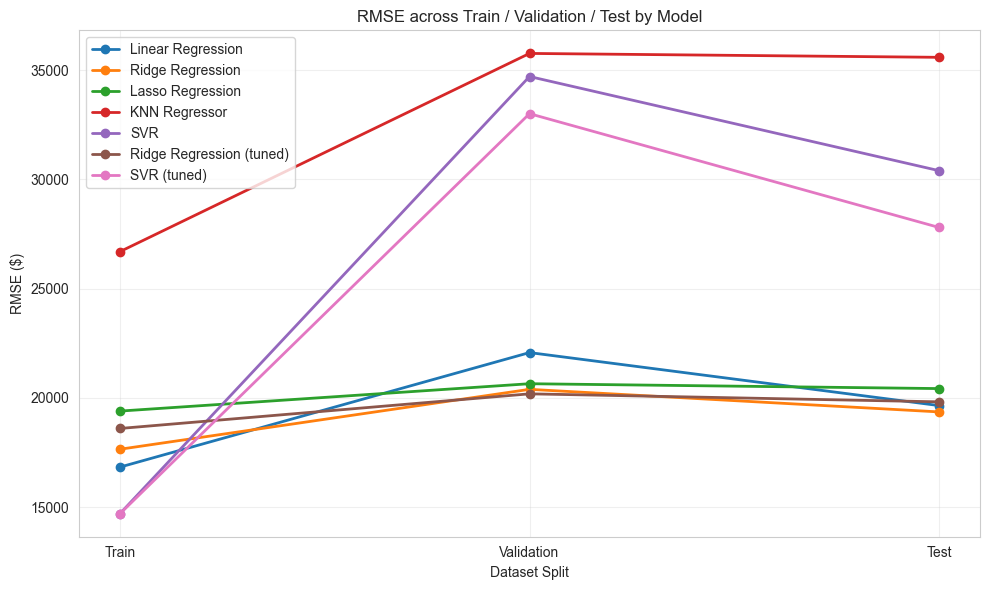

In [51]:
# Make sure the splits appear in the correct order
split_order = ["Train", "Validation", "Test"]

plt.figure(figsize=(10, 6))

for model in full_comparison["Model"].unique():

    model_data = (
        full_comparison[
            full_comparison["Model"] == model
        ]
        .set_index("Split")
        .reindex(split_order)
    )

    plt.plot(
        split_order,
        model_data["RMSE"],
        marker="o",
        linewidth=2,
        label=model
    )

plt.xlabel("Dataset Split")
plt.ylabel("RMSE ($)")
plt.title("RMSE across Train / Validation / Test by Model")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

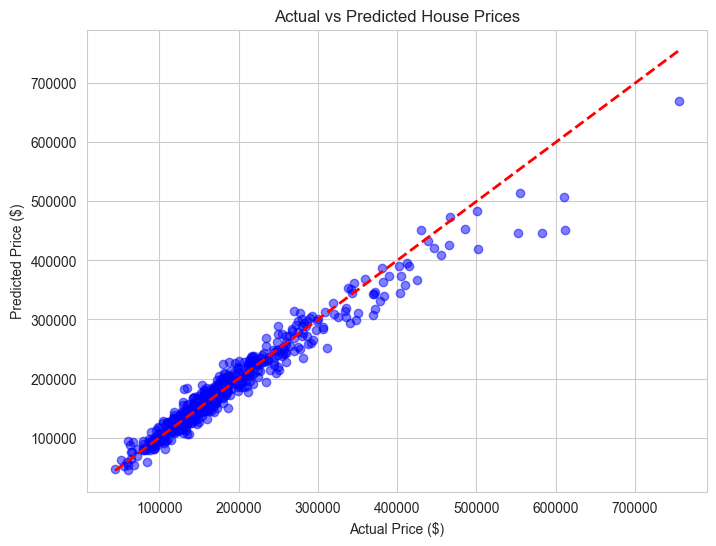

In [52]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_actual, y_pred_actual, alpha=0.5, color='blue')
plt.plot([y_test_actual.min(), y_test_actual.max()], [y_test_actual.min(), y_test_actual.max()], 'r--', lw=2)
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs Predicted House Prices')
plt.show()

**Discussion:**

- **Which model performs best?** **Ridge Regression (tuned)** is the strongest overall choice: R² of 0.939 (train) / 0.940 (validation) / 0.951 (test), with MAE around \$12.7k-13.7k and RMSE around \$18.6k-20.2k across all three splits. Its untuned counterpart (default `alpha=10`) is nearly identical (R² 0.945 / 0.939 / 0.954) -- tuning nudged `alpha` up to 50 and improved validation R² slightly (0.9387 -> 0.9399), but the effect is small. **Plain Linear Regression** and **Lasso** are close behind (test R² 0.952 and 0.948) but Ridge's regularization makes it the more robust choice given how many one-hot-encoded columns feed into a linear model here.
- **Evidence of overfitting?** **SVR is the clearest case**: train R² = 0.962 but validation R² drops to 0.822 (default) -- a ~14-point gap that is a textbook overfitting signature. Tuning narrows this gap (validation R² rises to 0.839, test to 0.904) by pushing `gamma` down to a smoother setting, but a meaningful train-validation gap remains even after tuning. **Ridge and Linear Regression show almost no such gap** (train and validation R² within ~1-2 points of each other), i.e. little to no overfitting.
- **Evidence of underfitting?** **KNN** is the weakest model on *every* split (train R² = 0.875, validation = 0.812, test = 0.843) -- unlike SVR, its problem isn't a train-validation gap, it simply doesn't fit the training data as well as the other models to begin with. This points to underfitting (or at least a poor match between plain Euclidean-distance KNN and a ~250-dimensional, mostly one-hot-encoded feature space), rather than overfitting.
- **Train vs. validation performance:** Ridge/Lasso/Linear Regression all show a small, healthy train-validation gap (within ~1-2 R² points); SVR's gap is much larger (~10-14 points), confirming it's the most overfitting-prone model of the five.
- **Does tuning help?** It helps **SVR** meaningfully (validation R² 0.822 -> 0.839, test 0.885 -> 0.904) by correcting an overly complex default `gamma`. It helps **Ridge** only marginally (validation R² 0.9387 -> 0.9399) since the untuned default (`alpha=10`) was already a reasonable regularization strength for this data.
- **Which model generalizes best?** **Ridge (tuned)**: its validation and test R² (0.940 / 0.951) are close to each other and to its training R² (0.939) -- performance doesn't collapse on unseen data, unlike SVR, and it doesn't underfit the way KNN does. This consistency, not just the raw R², is why it's selected as the best model in Section 6/7 above.

# 9. Feature Importance & Interpretation

Since the selected model, **Ridge Regression**, is linear, its fitted `coef_` values (on the standardized, log-transformed feature space) directly indicate each feature's estimated effect on log(SalePrice), holding the other features fixed -- larger absolute coefficients mean a bigger estimated impact on price. (Had a non-linear model like SVR been selected instead, permutation importance would be used, as already implemented below for that case.)

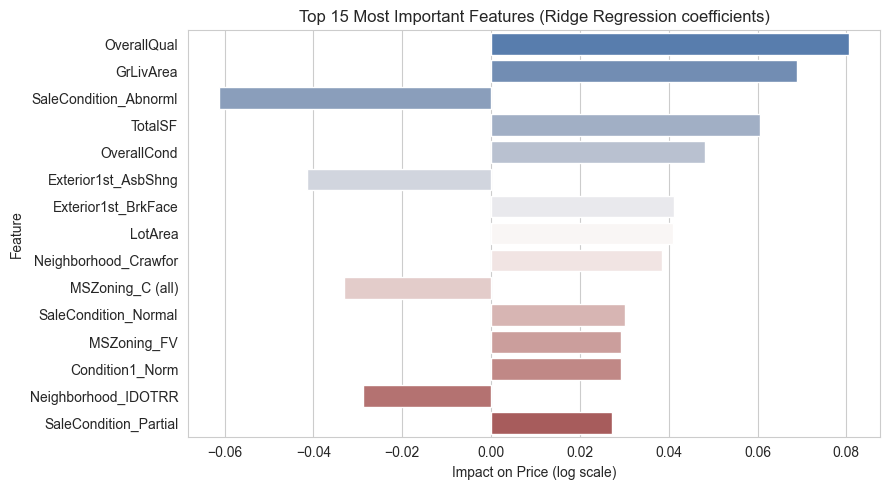

In [53]:
# 1. Extract feature importance. Ridge has coef_; SVR (rbf kernel) does not,
# so we fall back to permutation importance for any non-linear winner.
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

if hasattr(best_model.named_steps['model'], 'coef_'):
    coefficients = best_model.named_steps['model'].coef_
    df_feat = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefficients})
    df_feat['Abs_Coef'] = df_feat['Coefficient'].abs()
    df_top = df_feat.sort_values(by='Abs_Coef', ascending=False).head(15)
    plot_title = f'Top 15 Most Important Features ({best_name} coefficients)'
else:
    perm = permutation_importance(
        best_model, X_test, y_test, n_repeats=10,
        random_state=RANDOM_STATE, scoring='neg_root_mean_squared_error'
    )
    df_feat = pd.DataFrame({'Feature': feature_names, 'Coefficient': perm.importances_mean})
    df_feat['Abs_Coef'] = df_feat['Coefficient'].abs()
    df_top = df_feat.sort_values(by='Abs_Coef', ascending=False).head(15)
    plot_title = f'Top 15 Most Important Features ({best_name}, permutation importance)'

# 2. Clean feature names for clean viewing
df_top['Feature'] = df_top['Feature'].str.replace(r'^(num|ord|nom)__', '', regex=True)  # fixed: cleanly strip the ColumnTransformer prefix

# 3. Plotting
plt.figure(figsize=(9, 5))
sns.barplot(data=df_top, x='Coefficient', y='Feature', palette='vlag')
plt.title(plot_title)
plt.xlabel('Impact on Price (log scale)')
plt.ylabel('Feature')
plt.grid(True, axis='x')
plt.tight_layout()
plt.show()


**Interpretation:**

- **`OverallQual`** and **`GrLivArea`** are, once again, the two strongest predictors -- consistent with both the correlation heatmap in the EDA (Section 2) and the `OverallQual`/`GrLivArea` groupby analyses in Section 3 (Data Analysis & Insights), which already flagged these as the variables most tightly linked to `SalePrice`.
- The engineered feature **`TotalSF`** (total finished square footage = basement + 1st floor + 2nd floor) ranks 4th, ahead of any of its individual components -- a good sign that combining the three size features in Section 4 captured real signal, not just redundant noise.
- **`SaleCondition_Abnorml`** (a negative coefficient) and **`SaleCondition_Partial`**/**`SaleCondition_Normal`** (positive) show that *how* a house was sold (foreclosure/short sale vs. a normal sale vs. a newly-built home sold before completion) matters almost as much as square footage -- this wasn't examined directly in the earlier EDA/insights sections and is a genuinely new finding from the modeling stage.
- **`Neighborhood_Crawfor`** (positive) and **`Neighborhood_IDOTRR`** (negative) appearing here echoes the neighborhood price gaps already found in Section 3's Neighborhood Analysis (Crawford was among the higher-priced neighborhoods there; IDOTRR -- Iowa DOT & Rail Road -- among the lower-priced ones), and the ANOVA test in that section confirming neighborhood has a statistically significant relationship with price.
- A few **`Exterior1st`** and **`MSZoning`** categories also show up with sizeable coefficients (e.g. `Exterior1st_BrkFace` positive, `Exterior1st_AsbShng` negative, `MSZoning_C (all)` negative) -- plausible (commercially-zoned homes and outdated asbestos-shingle siding both being associated with lower prices), though each is a single category with a smaller sample size than the top numeric features, so these should be read as suggestive rather than as strongly as `OverallQual`/`GrLivArea`.
- **Caveat:** Ridge coefficients are estimated *jointly*, so features that are correlated with each other (e.g. `TotalSF` and its underlying square-footage components, or `OverallQual` and `OverallCond`) share credit for the same signal -- a coefficient near zero doesn't necessarily mean a feature is unimportant on its own, only that it adds little *beyond* what the other features already explain.

# 10.Final Model Selection 

##### Ridge Regression (tuned) was selected as the final model.It achieved strong validation and test performance while maintaining consistentperformance across the train, validation, and test sets. The small differencebetween training and validation R² indicates good generalization and limitedoverfitting.Ridge was preferred over the other models because its L2 regularization helpscontrol the coefficients in the high-dimensional feature space created byone-hot encoding. KNN showed weaker performance, while SVR showed a largertrain-validation gap and stronger overfitting behavior.